<a href="https://colab.research.google.com/github/Alex-So-Ma/Data_Analysis/blob/main/Proyecto_Introducci%C3%B3n_al_Aprendizaje_Autom%C3%A1tico_(Alejandro_Soto_Malpica).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **PROYECTO: INTRODUCCIÓN AL APRENDIZAJE AUTOMÁTICO**

Una vez visto el ***Módulo 5: Introducción al Aprendizaje Automático***, se presenta la siguiente actividad para que el alumnado pueda poner a prueba lo aprendido durante este módulo.

Dentro de la siguiente dinámica, realizar el siguiente **proyecto integrador**. En este proyecto se verá todo lo aprendido durante el **master en data science**.

Por lo que, el procedimiento a resolver es libre mientras se cumplan los puntos solicitados dentro de la descripción.

Puede descargar el conjunto de datos desde [aquí](https://docs.google.com/spreadsheets/d/1EvSrAe5JUoDUjU4x8Mm43q41Zecnov0wL4h8BbOT18M/edit?usp=drive_link).

## **ANÁLISIS DE TAMAÑO DE MERCADO DE VEHÍCULOS ELÉCTRICOS**

El análisis del tamaño del mercado es un aspecto crucial de la investigación de mercado que determina el volumen potencial de ventas dentro de un mercado determinado. Ayuda a las empresas a comprender la magnitud de la demanda, evaluar los niveles de saturación del mercado e identificar oportunidades de crecimiento. En este proyecto, Iicill lo llevará a través de la tarea de análisis de tamaño de mercado de Vehículos Eléctricos usando Python.

El análisis de tamaño de mercado para vehículos eléctricos implica un proceso de varios pasos que incluye definir el alcance del mercado, recopilar y preparar datos, modelar analíticamente y comunicar los hallazgos a través de visualización e informes. A continuación se muestra el proceso que puede seguir para la tarea de análisis de tamaño de mercado de vehículos eléctricos:

1.   Definir si el análisis es global, regional o centrado en países específicos.

2.   Recopilar información de asociaciones de la industria, empresas de investigación de mercado (por ejemplo, BloombergNEF, AIE) y publicaciones gubernamentales relevantes para el mercado de EV*.

3.   Utilice datos históricos para identificar tendencias en ventas, producción y mercado de EV*.

4.   Analice el tamaño del mercado y las tasas de crecimiento para diferentes segmentos de EV*.

5.   Según el análisis del tamaño del mercado, proporcione recomendaciones estratégicas para las empresas que buscan ingresar o expandirse en el mercado de EV* a través de predicciones.

_*NOTA: EV significa Electric Vehicles_

#Recopilación de datos

Los datos están en un archivo .csv que se descargó de la página:

https://data.wa.gov/Transportation/Electric-Vehicle-Population-Data/f6w7-q2d2/about_data

Es un conjunto de datos sobre veículos electricos con baterías (BEV por sus siglas en inglés) e híbridos enchufables (PHEV por sus siglas en inglés). Únicamente tiene información de vehículos registrados en el Washington State Department of Licensing. La última actualización, al tiempo de la descarga del archivo, fue el 12 de junio de 2026 y fue creado el 16 de abril de 2019.

In [ ]:
# Importa la herramienta para conectar Google Drive con Colab
from google.colab import drive

# Conecta Google Drive y lo hace accesible como una carpeta en /content/drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# Importa las librerías necesarias para el proyecto

import pandas as pd          # Manejo y análisis de tablas de datos
import numpy as np           # Operaciones matemáticas y manejo de números
import seaborn as sns        # Creación de gráficas con mejor diseño visual
import matplotlib.pyplot as plt  # Herramienta base para mostrar y personalizar gráficas

In [ ]:
# Ruta donde está guardado el archivo CSV dentro de Google Drive
ruta_colab = '/content/drive/MyDrive/Curso AD/Cuarto Módulo/Introducción al Aprendizaje Automático/Electric_Vehicle_Population_Data_20260617.csv'

# Lee el archivo CSV y lo carga en una tabla de datos llamada df_ev_population_data
df_ev_population_data = pd.read_csv(ruta_colab)

In [ ]:
# Muestra un resumen general de la tabla: columnas, tipo de dato de cada una y cuántos valores vacíos hay
df_ev_population_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 287763 entries, 0 to 287762
Data columns (total 16 columns):
 #   Column                                             Non-Null Count   Dtype  
---  ------                                             --------------   -----  
 0   VIN (1-10)                                         287763 non-null  object 
 1   County                                             287754 non-null  object 
 2   City                                               287754 non-null  object 
 3   State                                              287763 non-null  object 
 4   Postal Code                                        287754 non-null  float64
 5   Model Year                                         287763 non-null  int64  
 6   Make                                               287763 non-null  object 
 7   Model                                              287763 non-null  object 
 8   Electric Vehicle Type                              287763 non-null  object

- VIN (1-10): son los primeros 10 caracteres del número de identificación de cada vehículo.

- County: es la subdivisión, o condado del estado de Washington, en donde reside el dueño del vehículo.

- City: es la ciudad, en el estado de Washington, en donde reside el dueño del vehículo.

- State: es el estado, de Estados Unidos, asociado con el registro. Hay registros asociados con otros estados, además de Washington.

- Postal Code: 5 digitos del código postal del dueño del vehículo.

- Model Year: año del modelo del vehículo. Información encontrada en el VIN.

- Make: compañia que manufactruró el vehículo. Información encontrada en el VIN.

- Model: modelo del vehículo. Información encontrada en el VIN.

- Electric Vehicle Type: distingue si el vehículo es puramente eléctrico o si es híbrido.

- Clean Alternative Fuel Vehicle (CAFV) Eligibility: categoriza si es un vehículo de combustible alternativo limpio (CAFV por sus siglas en inglés) basádonse en los requerimientos en la legislación 2042 aprobada durante la sesion legislativa de 2019.

- Electric Range: describe que tan lejos puede llega un vehículo solo con la carga eléctrica.

- Legislative District: sección específica en donde reside el dueño, según la representación de la legislatura del estado.

- DOL Vehicle ID: número de identificación asignado por el Department of Licensing.

- Vehicle Location: centro del área identificada por el código postal.

- Electric Utility: Estas son las áreas de servicio minorista de energía eléctrica que dan servicio a la dirección del vehículo registrado.

- 2020 Census Tract: El identificador del distrito censal es una combinación de los códigos de estado, condado y distrito censal asignados por la Oficina del Censo de los Estados Unidos en el censo de 2020, también conocido como identificador geográfico (GEOID).

Podemos ver que el conjunto de datos tiene pocas columnas numéricas y de estas, solo Electric Range tiene valores comparables y ordenables, el resto son para identficas zonas geodráficas. Model Year podría ser el otro valor númerico que se puede usar igual que Electric Range.

In [ ]:
df_ev_population_data.head()

,VIN (1-10),County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,DOL Vehicle ID,Vehicle Location,Electric Utility,2020 Census Tract
0,YV4H60PE7S,Kitsap,Bremerton,WA,98310.0,2025,VOLVO,XC90,Plug-in Hybrid Electric Vehicle (PHEV),Clean Alternative Fuel Vehicle Eligible,32.0,23.0,277607004,POINT (-122.61136 47.5752),PUGET SOUND ENERGY INC,5.303508e+10
1,5YJ3E1EB3K,Snohomish,Lynnwood,WA,98087.0,2019,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,220.0,21.0,478641796,POINT (-122.27981 47.85727),PUGET SOUND ENERGY INC,5.306104e+10
2,1FADP5CUXD,Kitsap,Port Orchard,WA,98367.0,2013,FORD,C-MAX,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,19.0,35.0,253249678,POINT (-122.68471 47.50524),PUGET SOUND ENERGY INC,5.303509e+10
3,5YJSA1H20E,Thurston,Yelm,WA,98597.0,2014,TESLA,MODEL S,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,208.0,2.0,131872905,POINT (-122.60735 46.94239),PUGET SOUND ENERGY INC,5.306701e+10
4,7SAYGDEE2P,Snohomish,Bothell,WA,98012.0,2023,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,1.0,260935657,POINT (-122.20105 47.84423),PUGET SOUND ENERGY INC,5.306105e+10


#Limpieza de datos

Primero vamos a eliminar columnas que no nos son útiles o redundantes:

- VIN (1-10): Es un número de identificación cuya información ya esta plasmada en Model Year, Make y Model. Esta columna es redundante.

- DOL Vehicle ID: Es un número único de identificación, no es de ninguna utilidad.

- Vehicle Location: esta relacionana al código postal. Es una columna redundante.

In [ ]:
#Revisamos duplicados
print(df_ev_population_data[df_ev_population_data.duplicated()])

Empty DataFrame
Columns: [VIN (1-10), County, City, State, Postal Code, Model Year, Make, Model, Electric Vehicle Type, Clean Alternative Fuel Vehicle (CAFV) Eligibility, Electric Range, Legislative District, DOL Vehicle ID, Vehicle Location, Electric Utility, 2020 Census Tract]
Index: []


No se encontraton duplicados.

In [ ]:
# Crea una copia de la tabla original eliminando las columnas que no se van a usar
df_ev_population_data_copy = df_ev_population_data.drop(columns=['VIN (1-10)', 'DOL Vehicle ID', 'Vehicle Location']).copy()

In [ ]:
# Cuenta y muestra cuántos valores vacíos hay en cada columna de la tabla
print(df_ev_population_data_copy.isnull().sum())

County                                                 9
City                                                   9
State                                                  0
Postal Code                                            9
Model Year                                             0
Make                                                   0
Model                                                  0
Electric Vehicle Type                                  0
Clean Alternative Fuel Vehicle (CAFV) Eligibility      0
Electric Range                                         9
Legislative District                                 740
Electric Utility                                       9
2020 Census Tract                                      9
dtype: int64


##Columnas de texo

De las columnas de texto, que tienen valores vacíos, podemos ver que son 9 filas las que les faltan estas 9 columnas.

In [ ]:
# Filtra las filas donde la columna 'County' está vacía
df_ev_population_data_copy[df_ev_population_data_copy['County'].isnull()]

,County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,Electric Utility,2020 Census Tract
420,NaN,NaN,BC,NaN,2022,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,NaN,NaN,NaN
455,NaN,NaN,BC,NaN,2025,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,NaN,NaN,NaN
159878,NaN,NaN,AE,NaN,2022,TOYOTA,PRIUS PRIME (PHEV),Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,25.0,NaN,NaN,NaN
265391,NaN,NaN,AP,NaN,2023,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,NaN,NaN,NaN
273337,NaN,NaN,BC,NaN,2017,TESLA,MODEL X,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,200.0,NaN,NaN,NaN
277980,NaN,NaN,NH,NaN,2010,TESLA,ROADSTER,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,245.0,NaN,NaN,NaN
280569,NaN,NaN,AE,NaN,2014,FORD,FUSION,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,19.0,NaN,NaN,NaN
282769,NaN,NaN,AE,NaN,2021,VOLKSWAGEN,ID.4,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,NaN,NaN,NaN
286754,NaN,NaN,QC,NaN,2022,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,NaN,NaN,NaN


In [ ]:
# Rellena los valores vacíos de cada columna con un texto que indica que no hay información disponible
df_ev_population_data_copy['County'] = df_ev_population_data_copy['County'].fillna('County N/A')           # Vacíos en 'County' se reemplazan con 'County N/A'
df_ev_population_data_copy['City'] = df_ev_population_data_copy['City'].fillna('City N/A')                 # Vacíos en 'City' se reemplazan con 'City N/A'
df_ev_population_data_copy['Electric Utility'] = df_ev_population_data_copy['Electric Utility'].fillna('Electric Utility N/A')  # Vacíos en 'Electric Utility' se reemplazan con 'Electric Utility N/A'

In [ ]:
# Filtra y muestra todas las filas donde la columna 'Postal Code' está vacía
df_ev_population_data_copy[df_ev_population_data_copy['Postal Code'].isnull()]

,County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,Electric Utility,2020 Census Tract
420,County N/A,City N/A,BC,NaN,2022,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,NaN,Electric Utility N/A,NaN
455,County N/A,City N/A,BC,NaN,2025,TESLA,MODEL 3,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,NaN,Electric Utility N/A,NaN
159878,County N/A,City N/A,AE,NaN,2022,TOYOTA,PRIUS PRIME (PHEV),Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,25.0,NaN,Electric Utility N/A,NaN
265391,County N/A,City N/A,AP,NaN,2023,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,NaN,Electric Utility N/A,NaN
273337,County N/A,City N/A,BC,NaN,2017,TESLA,MODEL X,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,200.0,NaN,Electric Utility N/A,NaN
277980,County N/A,City N/A,NH,NaN,2010,TESLA,ROADSTER,Battery Electric Vehicle (BEV),Clean Alternative Fuel Vehicle Eligible,245.0,NaN,Electric Utility N/A,NaN
280569,County N/A,City N/A,AE,NaN,2014,FORD,FUSION,Plug-in Hybrid Electric Vehicle (PHEV),Not eligible due to low battery range,19.0,NaN,Electric Utility N/A,NaN
282769,County N/A,City N/A,AE,NaN,2021,VOLKSWAGEN,ID.4,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,NaN,Electric Utility N/A,NaN
286754,County N/A,City N/A,QC,NaN,2022,TESLA,MODEL Y,Battery Electric Vehicle (BEV),Eligibility unknown as battery range has not b...,0.0,NaN,Electric Utility N/A,NaN


In [ ]:
# Define una función para limpiar el texto de las columnas
def limpiar_texto(texto):
    import re  # Librería para buscar y reemplazar patrones de texto
    if pd.isna(texto): return texto  # Si el valor está vacío, lo deja como está
    texto = re.sub(r'[^a-zA-ZáéíóúÁÉÍÓÚñÑ\s]', '', str(texto))  # Elimina todo excepto letras y espacios
    return texto.lower()  # Convierte el texto a minúsculas

# Lista de columnas de texto que se van a limpiar
columnas_texto = ['County', 'City', 'State', 'Make', 'Electric Vehicle Type', 'Clean Alternative Fuel Vehicle (CAFV) Eligibility', 'Electric Utility']

# Aplica la función de limpieza a cada columna de la lista
for i in columnas_texto:
  df_ev_population_data_copy[i] = df_ev_population_data_copy[i].apply(limpiar_texto)

##Columnas numéricas

In [ ]:
print(df_ev_population_data_copy.isnull().sum())

County                                                 0
City                                                   0
State                                                  0
Postal Code                                            9
Model Year                                             0
Make                                                   0
Model                                                  0
Electric Vehicle Type                                  0
Clean Alternative Fuel Vehicle (CAFV) Eligibility      0
Electric Range                                         9
Legislative District                                 740
Electric Utility                                       0
2020 Census Tract                                      9
dtype: int64


De las columnas numéricas, con valores vacíaos, podemos ver que tres son realment números que se usan como identificadores. O sea, son como un nombre, por lo tanto, trataremos estas columnas como texto.

In [ ]:
# Rellena los valores vacíos con 0 de forma temporal para poder convertir el tipo de dato
df_ev_population_data_copy['Postal Code'] = df_ev_population_data_copy['Postal Code'].fillna(0)
df_ev_population_data_copy['Legislative District'] = df_ev_population_data_copy['Legislative District'].fillna(0)
df_ev_population_data_copy['2020 Census Tract'] = df_ev_population_data_copy['2020 Census Tract'].fillna(0)

# Convierte las columnas a número entero (necesario antes de convertir a texto, para evitar decimales como "0.0")
df_ev_population_data_copy['Postal Code'] = df_ev_population_data_copy['Postal Code'].astype(int)
df_ev_population_data_copy['Legislative District'] = df_ev_population_data_copy['Legislative District'].astype(int)
df_ev_population_data_copy['2020 Census Tract'] = df_ev_population_data_copy['2020 Census Tract'].astype(int)

# Convierte las columnas a texto para poder reemplazar el 0 por una etiqueta descriptiva
df_ev_population_data_copy['Postal Code'] = df_ev_population_data_copy['Postal Code'].astype(str)
df_ev_population_data_copy['Legislative District'] = df_ev_population_data_copy['Legislative District'].astype(str)
df_ev_population_data_copy['2020 Census Tract'] = df_ev_population_data_copy['2020 Census Tract'].astype(str)

# Reemplaza el '0' por un texto que indica que no hay información disponible
df_ev_population_data_copy['Postal Code'] = df_ev_population_data_copy['Postal Code'].replace('0', 'Postal Code N/A')
df_ev_population_data_copy['Legislative District'] = df_ev_population_data_copy['Legislative District'].replace('0', 'Legislative District N/A')
df_ev_population_data_copy['2020 Census Tract'] = df_ev_population_data_copy['2020 Census Tract'].replace('0', '2020 Census Tract N/A')

Ahora vamos con la columna que sí es un valor numérico que podemos tratarlo como tal.

In [ ]:
# Filtra las filas donde la columna 'Electric Range' está vacía y muestra las primeras 10
df_ev_population_data_copy[df_ev_population_data_copy['Electric Range'].isnull()].head(10)

,County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,Electric Utility,2020 Census Tract
24631,king,mercer island,wa,98040,2025,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,41,puget sound energy inccity of tacoma wa,53033024302
28029,king,seattle,wa,98121,2026,lamborghini,TEMERARIO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,36,city of seattle wacity of tacoma wa,53033008002
49327,king,bellevue,wa,98006,2025,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,41,puget sound energy inccity of tacoma wa,53033023902
117641,king,mercer island,wa,98040,2026,lamborghini,TEMERARIO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,41,puget sound energy inccity of tacoma wa,53033024601
148251,king,sammamish,wa,98075,2025,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,41,puget sound energy inccity of tacoma wa,53033032217
150050,yakima,naches,wa,98937,2025,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,14,pacificorp,53077002900
154069,snohomish,snohomish,wa,98296,2025,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,1,puget sound energy inc,53061052107
208990,spokane,spokane,wa,99005,2025,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,7,bonneville power administrationinland power l...,53063010504
219314,pierce,gig harbor,wa,98332,2026,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,26,bonneville power administrationcity of tacoma ...,53053072509


Podemos ver que los valores nulos en la columna Electric Range, le pertenecen a dos modelos de Lamborghini.

In [ ]:
# Filtra y muestra todas las filas donde el modelo del vehículo es 'REVUELTO'
df_ev_population_data_copy[df_ev_population_data_copy['Model'] == 'REVUELTO']

,County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,Electric Utility,2020 Census Tract
24631,king,mercer island,wa,98040,2025,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,41,puget sound energy inccity of tacoma wa,53033024302
49327,king,bellevue,wa,98006,2025,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,41,puget sound energy inccity of tacoma wa,53033023902
101476,benton,richland,wa,99352,2024,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,not eligible due to low battery range,6.0,8,bonneville power administrationcity of richlan...,53005010817
144577,king,redmond,wa,98053,2024,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,not eligible due to low battery range,6.0,45,puget sound energy inccity of tacoma wa,53033032315
148251,king,sammamish,wa,98075,2025,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,41,puget sound energy inccity of tacoma wa,53033032217
150050,yakima,naches,wa,98937,2025,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,14,pacificorp,53077002900
154069,snohomish,snohomish,wa,98296,2025,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,1,puget sound energy inc,53061052107
208595,pierce,edgewood,wa,98371,2024,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,not eligible due to low battery range,6.0,31,puget sound energy inccity of tacoma wa,53053940009
208990,spokane,spokane,wa,99005,2025,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,7,bonneville power administrationinland power l...,53063010504
219314,pierce,gig harbor,wa,98332,2026,lamborghini,REVUELTO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,26,bonneville power administrationcity of tacoma ...,53053072509


Podemos ver que para el lamborguini Revuelto, tenemos otras filas donde sí se tiene el rango de este modelo. Al ser el mismo modelo, podemos asumir que los que tienen la columna vacía tiene el mismo rango.

In [ ]:
# Filtra y muestra todas las filas donde el modelo del vehículo es 'TEMERARIO'
df_ev_population_data_copy[df_ev_population_data_copy['Model'] == 'TEMERARIO']

,County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,Electric Utility,2020 Census Tract
28029,king,seattle,wa,98121,2026,lamborghini,TEMERARIO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,36,city of seattle wacity of tacoma wa,53033008002
117641,king,mercer island,wa,98040,2026,lamborghini,TEMERARIO,plugin hybrid electric vehicle phev,clean alternative fuel vehicle eligible,NaN,41,puget sound energy inccity of tacoma wa,53033024601


De acuerdo a la página de wikipedia del Lamborghini Temerario:

https://en.wikipedia.org/wiki/Lamborghini_Temerario

"The Temerario uses the existing 3.8 kWh battery pack from the Lamborghini Revuelto". En español: "El Lamborghini Temerario usa la batería de 3.8 kWh existente del Lamborghini Revuelto". Es decir, podemos usar el Electric Range del Lamborghini Revuelto para el Lamborghini Temerario.

In [ ]:
# Asigna el valor 6.0 en la columna 'Electric Range' a todos los vehículos cuyo modelo es 'REVUELTO'
df_ev_population_data_copy.loc[df_ev_population_data_copy['Model'] == 'REVUELTO', 'Electric Range'] = 6.0

# Asigna el valor 6.0 en la columna 'Electric Range' a todos los vehículos cuyo modelo es 'TEMERARIO'
df_ev_population_data_copy.loc[df_ev_population_data_copy['Model'] == 'TEMERARIO', 'Electric Range'] = 6.0

In [ ]:
print(df_ev_population_data_copy.isnull().sum())

County                                               0
City                                                 0
State                                                0
Postal Code                                          0
Model Year                                           0
Make                                                 0
Model                                                0
Electric Vehicle Type                                0
Clean Alternative Fuel Vehicle (CAFV) Eligibility    0
Electric Range                                       0
Legislative District                                 0
Electric Utility                                     0
2020 Census Tract                                    0
dtype: int64


In [ ]:
df_ev_population_data_copy[df_ev_population_data_copy['Electric Range'] == 0]

,County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,Electric Utility,2020 Census Tract
4,snohomish,bothell,wa,98012,2023,tesla,MODEL Y,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,1,puget sound energy inc,53061051927
13,kitsap,poulsbo,wa,98370,2024,tesla,MODEL Y,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,23,puget sound energy inc,53035940100
23,kitsap,poulsbo,wa,98370,2023,volkswagen,ID.4,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,23,puget sound energy inc,53035090502
29,kitsap,silverdale,wa,98383,2023,kia,EV6,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,23,puget sound energy inc,53035091205
30,yakima,yakima,wa,98902,2024,chevrolet,EQUINOX,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,14,pacificorp,53077001202
...,...,...,...,...,...,...,...,...,...,...,...,...,...
287756,thurston,yelm,wa,98597,2023,tesla,MODEL Y,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,2,puget sound energy inc,53067012421
287757,spokane,spokane,wa,99205,2024,subaru,SOLTERRA,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,3,modern electric water company,53063001300
287759,benton,richland,wa,99352,2022,porsche,TAYCAN,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,8,bonneville power administrationcity of richlan...,53005010811
287760,whatcom,ferndale,wa,98248,2025,subaru,SOLTERRA,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,42,puget sound energy incpud no of whatcom county,53073010506


Ahora vamos a revisar valores de no son nulos, pero que no corresponden a los valores de Electric Range para un vehículo eléctrico o híbrido. Es decir, cuando son cero.

In [ ]:
# Agrupa los vehículos por modelo y cuenta cuántas marcas diferentes tienen ese mismo nombre de modelo
modelos_compartidos = df_ev_population_data_copy.groupby('Model')['Make'].nunique()

# Muestra solo los modelos que son compartidos por más de una marca
print(modelos_compartidos[modelos_compartidos > 1])

Series([], Name: Make, dtype: int64)


No hay nombres de modelo compartidos en más de una marca o fabricante.

In [ ]:
# Recorre cada modelo que tenga al menos un registro con 'Electric Range' igual a 0
for i in df_ev_population_data_copy[df_ev_population_data_copy['Electric Range'] == 0]['Model'].unique():

  # Busca otros registros del mismo modelo que sí tengan un valor válido de 'Electric Range'
  df = df_ev_population_data_copy[
    (df_ev_population_data_copy['Model'] == i) &
    (df_ev_population_data_copy['Electric Range'] != 0)
  ]

  # Si encontró al menos un valor válido, reemplaza los 0 de ese modelo con el valor más alto encontrado
  if len(df['Electric Range'].unique()) >= 1:
    df_ev_population_data_copy.loc[(df_ev_population_data_copy['Model'] == i) & (df_ev_population_data_copy['Electric Range'] == 0),'Electric Range'] = df['Electric Range'].max()

Ahora, reemplazamos los valores en 0 por valores, de esos mismo modelos, ya conocidos de la información existente en el conjunto de datos. Si no hay valores distintos de 0 en los datos, los dejamos en 0. Si hay más de un valor, usamos el más alto. Al ser el mismo modelo, deberían tener todos el mismo rango. A los que no tienen el rango máximo registrado no los cambiamos, ya que no hay razón para alterar registros distintos a 0, que es el valor que no es razonable.

In [ ]:
df_ev_population_data_copy[df_ev_population_data_copy['Electric Range'] == 0]

,County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,Electric Utility,2020 Census Tract
23,kitsap,poulsbo,wa,98370,2023,volkswagen,ID.4,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,23,puget sound energy inc,53035090502
29,kitsap,silverdale,wa,98383,2023,kia,EV6,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,23,puget sound energy inc,53035091205
30,yakima,yakima,wa,98902,2024,chevrolet,EQUINOX,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,14,pacificorp,53077001202
31,kitsap,olalla,wa,98359,2025,hyundai,IONIQ 5,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,26,puget sound energy inc,53035092803
71,kitsap,poulsbo,wa,98370,2022,kia,EV6,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,23,puget sound energy inc,53035940100
...,...,...,...,...,...,...,...,...,...,...,...,...,...
287749,thurston,olympia,wa,98506,2025,jeep,WAGONEER S,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,22,puget sound energy inc,53067012223
287754,clark,camas,wa,98607,2024,audi,Q8,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,18,bonneville power administrationpud no of clar...,53011040609
287757,spokane,spokane,wa,99205,2024,subaru,SOLTERRA,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,3,modern electric water company,53063001300
287760,whatcom,ferndale,wa,98248,2025,subaru,SOLTERRA,battery electric vehicle bev,eligibility unknown as battery range has not b...,0.0,42,puget sound energy incpud no of whatcom county,53073010506


##Valores atípicos

In [ ]:
df_ev_population_data_copy.describe()

,Model Year,Electric Range
count,287763.000000,287763.000000
mean,2022.207299,144.958007
std,3.075325,134.007398
min,1999.000000,0.000000
25%,2021.000000,0.000000
50%,2023.000000,93.000000
75%,2024.000000,291.000000
max,2027.000000,337.000000


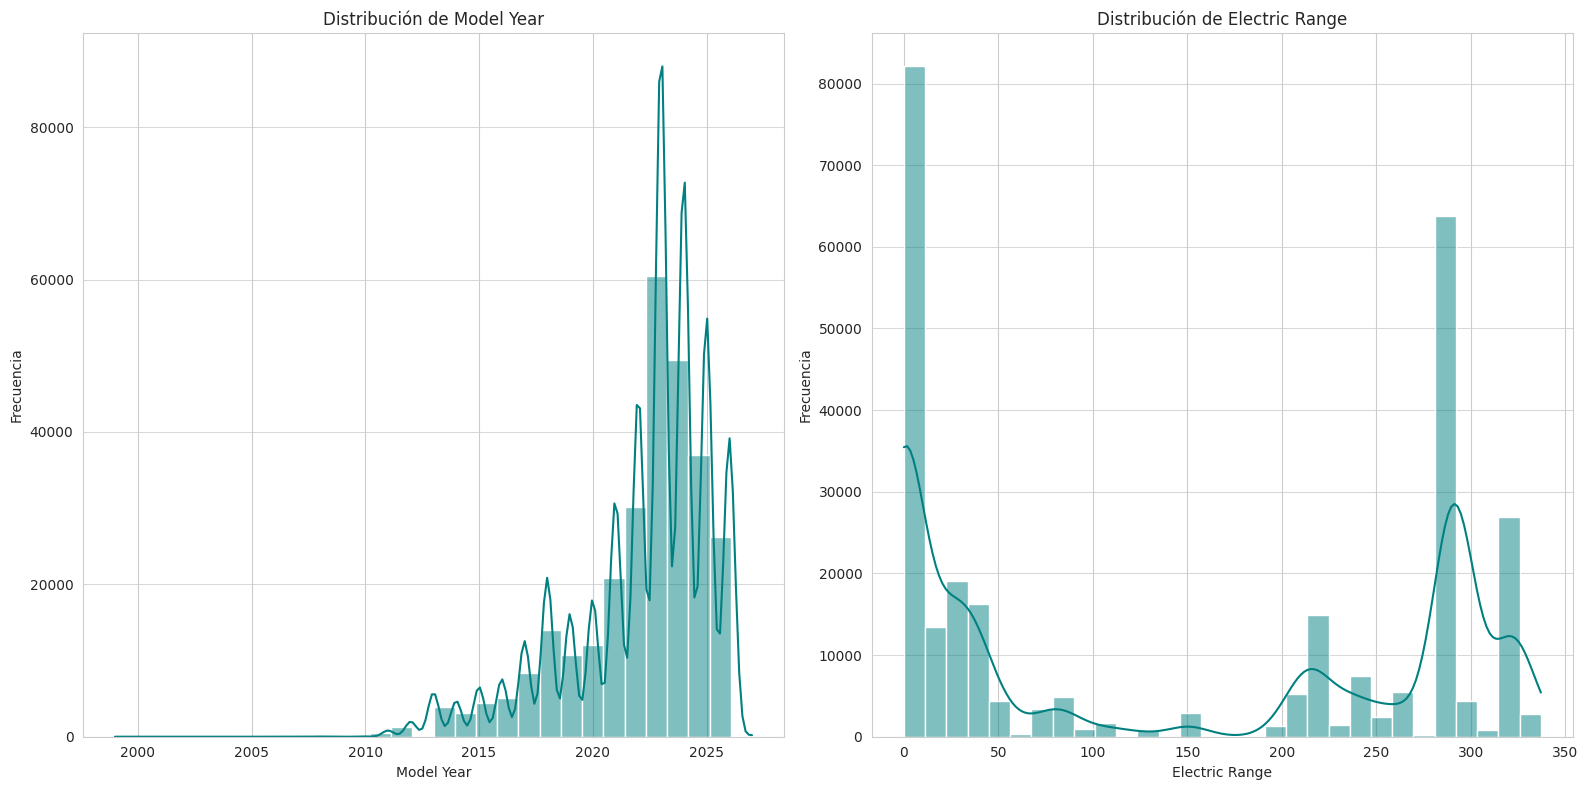

In [ ]:
# Define las columnas numéricas que se van a graficar
columnas_numericas = ['Model Year', 'Electric Range']

# Crea un lienzo de 16x8 pulgadas para colocar las gráficas
plt.figure(figsize=(16, 8))

# Recorre cada columna y crea una gráfica por cada una
for i, col in enumerate(columnas_numericas, 1):
    plt.subplot(1, 2, i)  # Divide el lienzo en 1 fila y 2 columnas, y coloca la gráfica en la posición i
    sns.histplot(df_ev_population_data_copy[col], bins=30, kde=True, color='teal')  # Dibuja un histograma con 30 barras y una curva de tendencia encima
    plt.title(f'Distribución de {col.replace("_", " ").title()}')  # Título de la gráfica
    plt.xlabel(col.replace("_", " ").title())  # Etiqueta del eje horizontal
    plt.ylabel('Frecuencia')  # Etiqueta del eje vertical
    plt.grid(axis='y', alpha=0.75)  # Agrega líneas de cuadrícula horizontales con algo de transparencia

plt.tight_layout()  # Ajusta el espaciado para que las gráficas no se encimen
plt.show()  # Muestra las gráficas

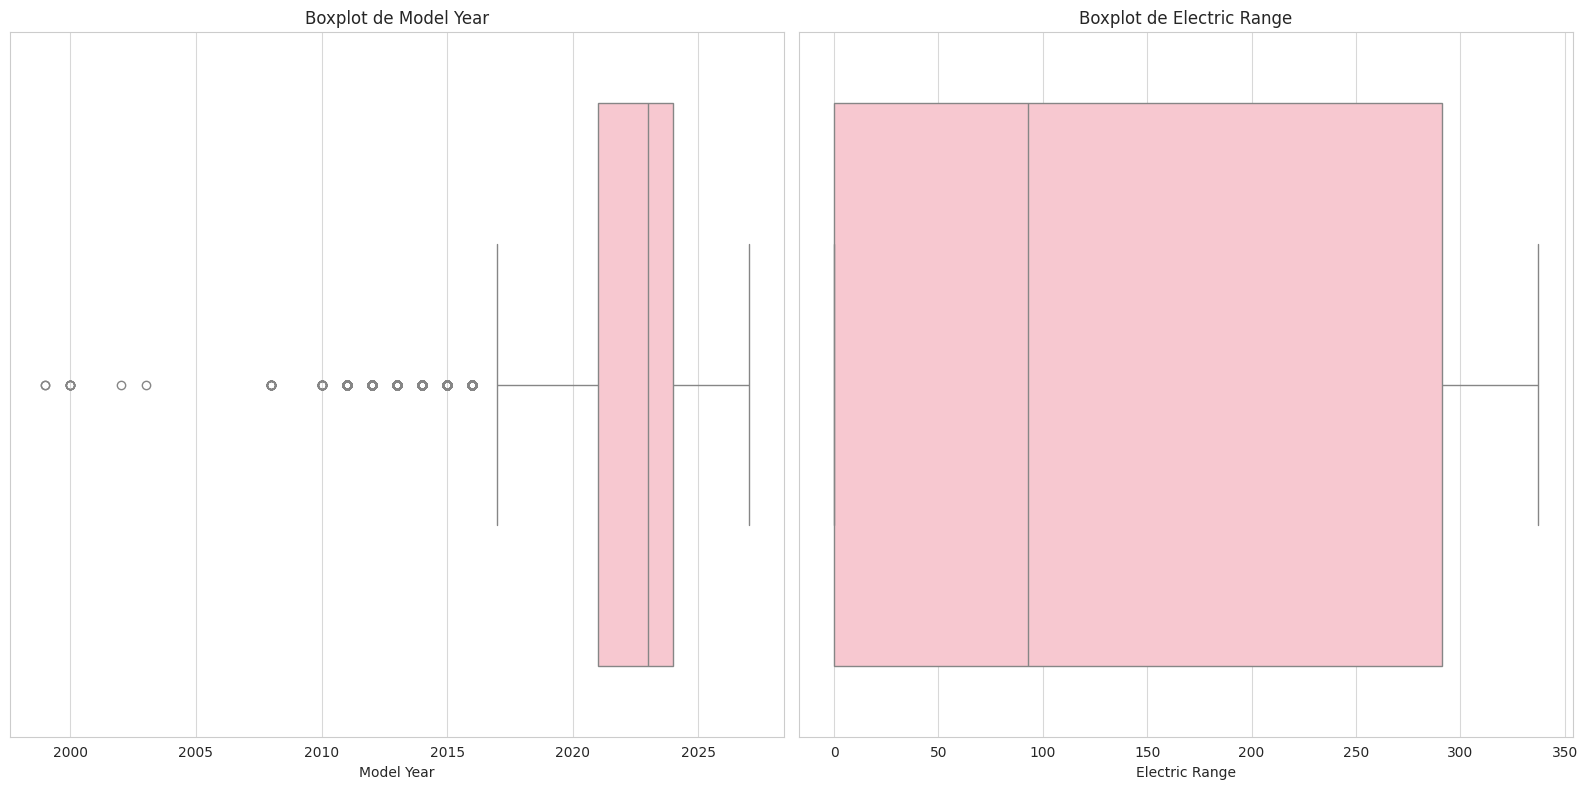

In [ ]:
# Observar comportamiento cuartil de los datos
plt.figure(figsize=(16, 8))  # Crea un lienzo de 16x8 pulgadas para colocar las gráficas

# Recorre cada columna y crea un boxplot por cada una
for i, col in enumerate(columnas_numericas, 1):
    plt.subplot(1, 2, i)  # Divide el lienzo en 1 fila y 2 columnas, y coloca la gráfica en la posición i
    sns.boxplot(x=df_ev_population_data_copy[col], color='pink')  # Dibuja un boxplot que muestra la distribución y valores atípicos de los datos
    plt.title(f'Boxplot de {col.replace("_", " ").title()}')  # Título de la gráfica
    plt.xlabel(col.replace("_", " ").title())  # Etiqueta del eje horizontal
    plt.grid(axis='x', alpha=0.75)  # Agrega líneas de cuadrícula verticales con algo de transparencia

plt.tight_layout()  # Ajusta el espaciado para que las gráficas no se encimen
plt.show()  # Muestra las gráficas

El valor atípico, en el caso del año del modelo, podría ser el modelo más viejo en el conjunto, el de 1999.

In [ ]:
df_ev_population_data_copy[df_ev_population_data_copy['Model Year'] == 1999]

,County,City,State,Postal Code,Model Year,Make,Model,Electric Vehicle Type,Clean Alternative Fuel Vehicle (CAFV) Eligibility,Electric Range,Legislative District,Electric Utility,2020 Census Tract
94719,pierce,graham,wa,98338,1999,ford,RANGER,battery electric vehicle bev,clean alternative fuel vehicle eligible,74.0,2,bonneville power administrationcity of tacoma ...,53053073116
98565,pierce,graham,wa,98338,1999,ford,RANGER,battery electric vehicle bev,clean alternative fuel vehicle eligible,74.0,2,bonneville power administrationcity of tacoma ...,53053073116


Sin embargo, la Ford Ranger EV es un modelo que si estuvo en producción, de acuerdo a su página de wikipedia:

https://en.wikipedia.org/wiki/Ford_Ranger_EV

"The Ford Ranger EV is a battery electric compact pickup truck that was produced by the Ford Motor Company and was the automaker's first all-electric production vehicle. It was produced starting in the 1998 model year through 2002 and is no longer in production". El vehículo estuvo en producción desde 1998 hasta 2002. Entonces, estos son datos válidos que no deben ser eliminados.

Para Electric Range no parece haber valores atípicos.

#Exploración de datos

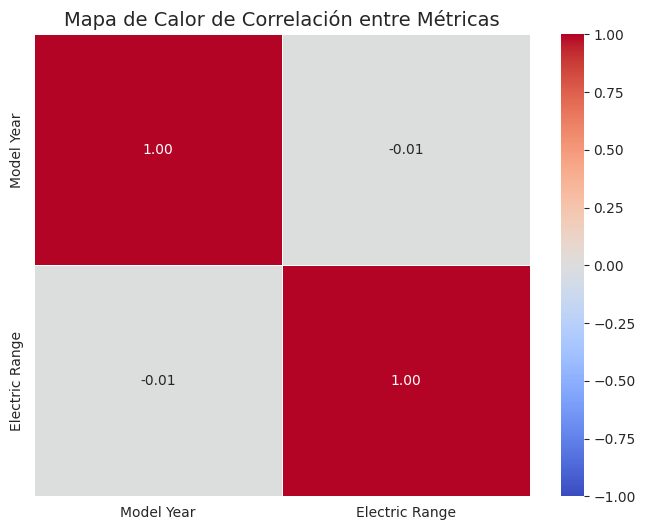

In [ ]:
# Calcula qué tan relacionadas están las columnas numéricas entre sí (valor entre -1 y 1)
corr_matrix = df_ev_population_data_copy[columnas_numericas].corr()

# Crea un lienzo de 8x6 pulgadas
plt.figure(figsize=(8, 6))

# Dibuja el mapa de calor con la matriz de correlación
# annot=True: muestra los valores dentro de cada celda
# cmap='coolwarm': usa colores que van del azul (correlación negativa) al rojo (correlación positiva)
# fmt=".2f": muestra los valores con 2 decimales
# linewidths=0.5: agrega líneas delgadas entre las celdas
# vmin=-1, vmax=1: fija los extremos de la escala de colores
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5, vmin=-1, vmax=1)

plt.title('Mapa de Calor de Correlación entre Métricas', fontsize=14)  # Título de la gráfica
plt.show()  # Muestra la gráfica

En el mapa de correlación, podemos ver que hay poca correlación entre las variables numéricas.

##Comparaciones

In [ ]:
# Crea una nueva tabla excluyendo los vehículos que tienen 'Electric Range' igual a 0
df_ev_population_data_copy_noer0 = df_ev_population_data_copy[df_ev_population_data_copy['Electric Range'] != 0]

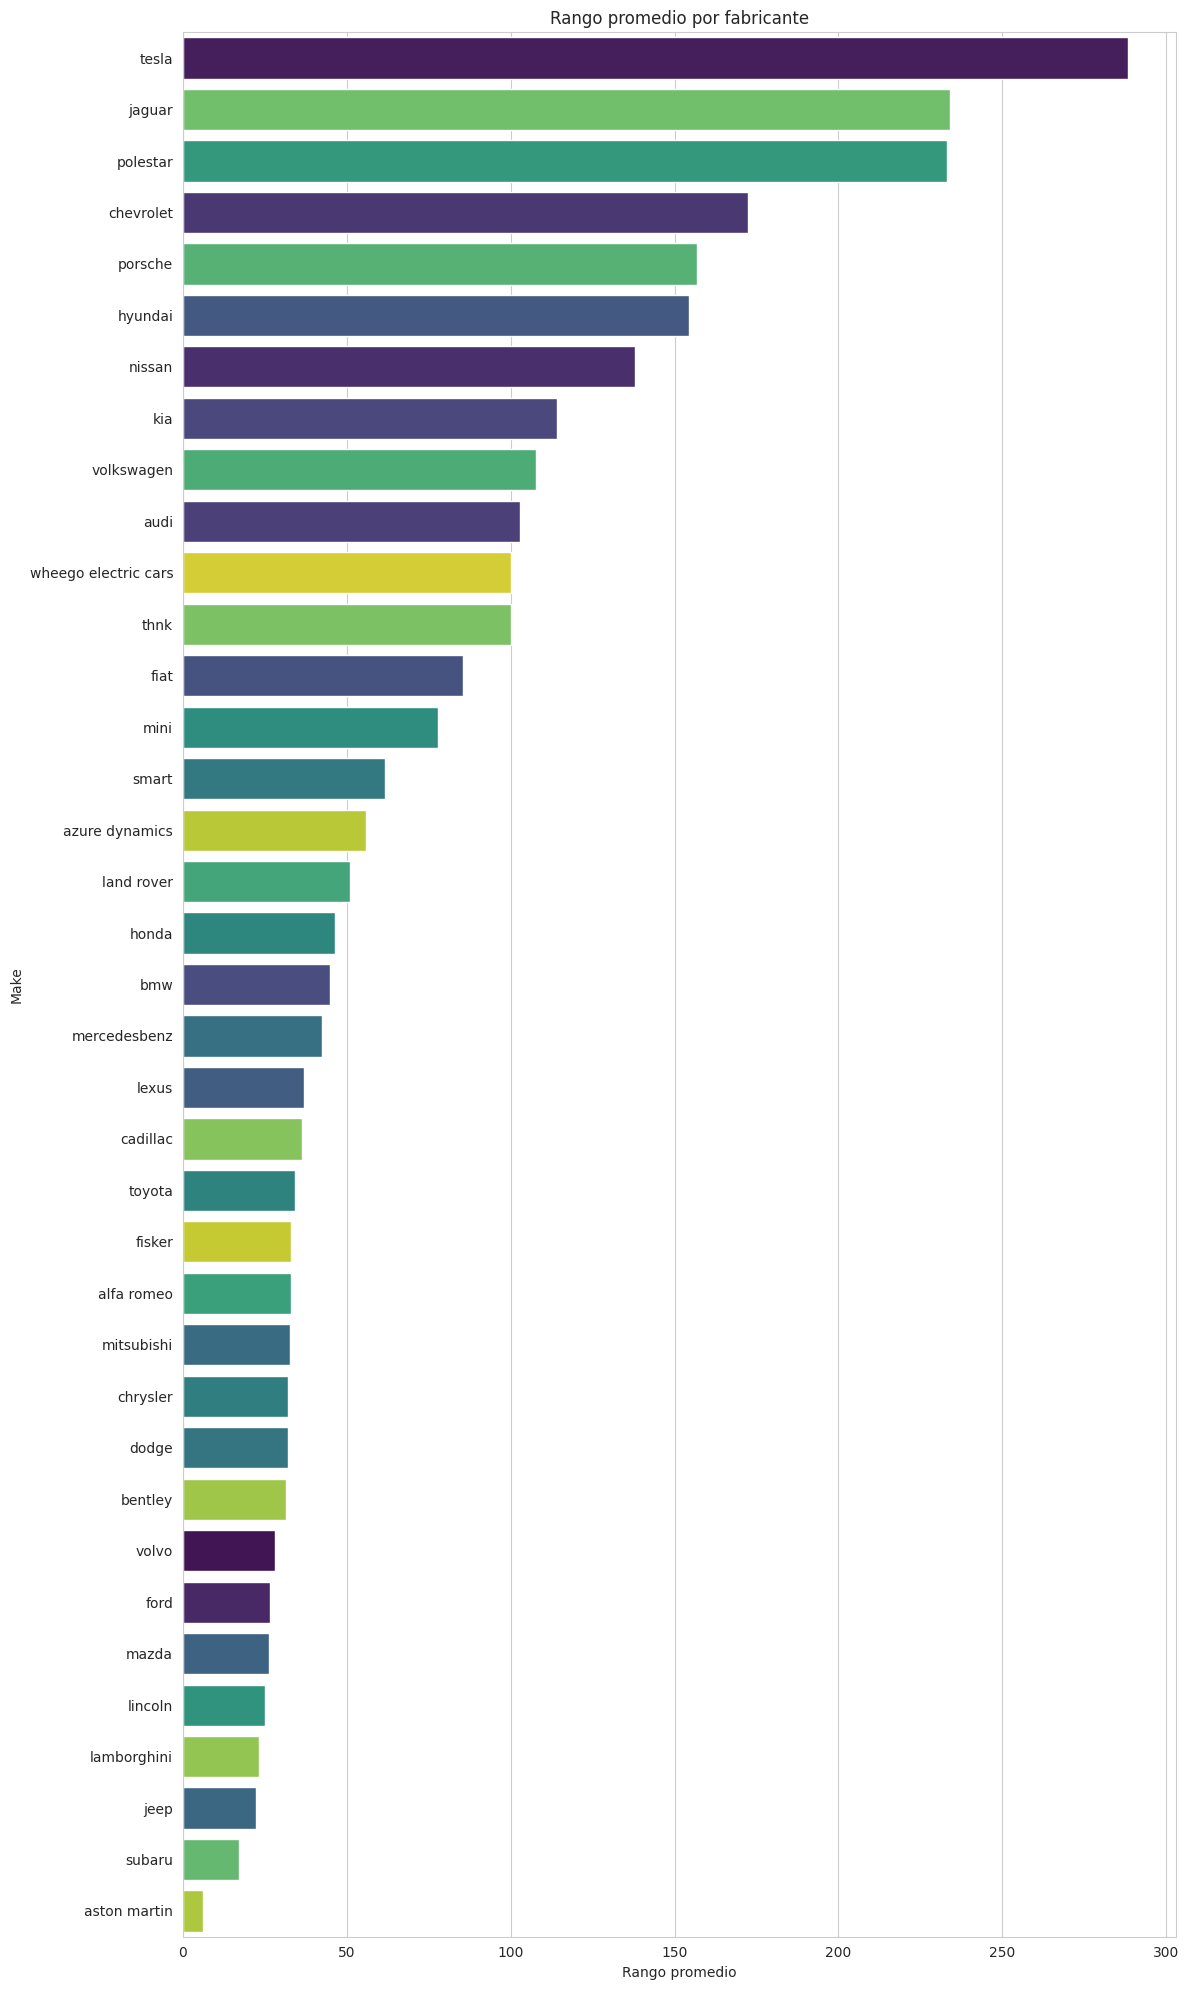

In [ ]:
# Calcula el rango eléctrico promedio por marca y los ordena de mayor a menor
order = df_ev_population_data_copy_noer0.groupby('Make')['Electric Range'].mean().sort_values().index[::-1]

# Crea un lienzo de 12x20 pulgadas (alto porque hay muchas marcas)
plt.figure(figsize=(12, 20))

# Dibuja una gráfica de barras horizontales con el rango promedio de cada marca
# estimator='mean': usa el promedio como valor de cada barra
# palette='viridis': aplica una paleta de colores degradada
# errorbar=None: no muestra barras de error
# hue='Make': colorea cada barra según la marca
# legend=False: oculta la leyenda de colores
sns.barplot(data=df_ev_population_data_copy_noer0, x='Electric Range', y='Make', order=order,
            estimator='mean', palette='viridis', errorbar=None, hue='Make', legend=False)

plt.title('Rango promedio por fabricante')  # Título de la gráfica
plt.xlabel('Rango promedio')  # Etiqueta del eje horizontal
plt.tight_layout()  # Ajusta el espaciado para que todo se vea bien
plt.show()  # Muestra la gráfica

En este gráfico podemos apreciar el rango promedio por fabricante (o marca). Podemos ver que Tesla es quien tiene un rango promedio más alto, de ahí el promedio va disminuyendo.

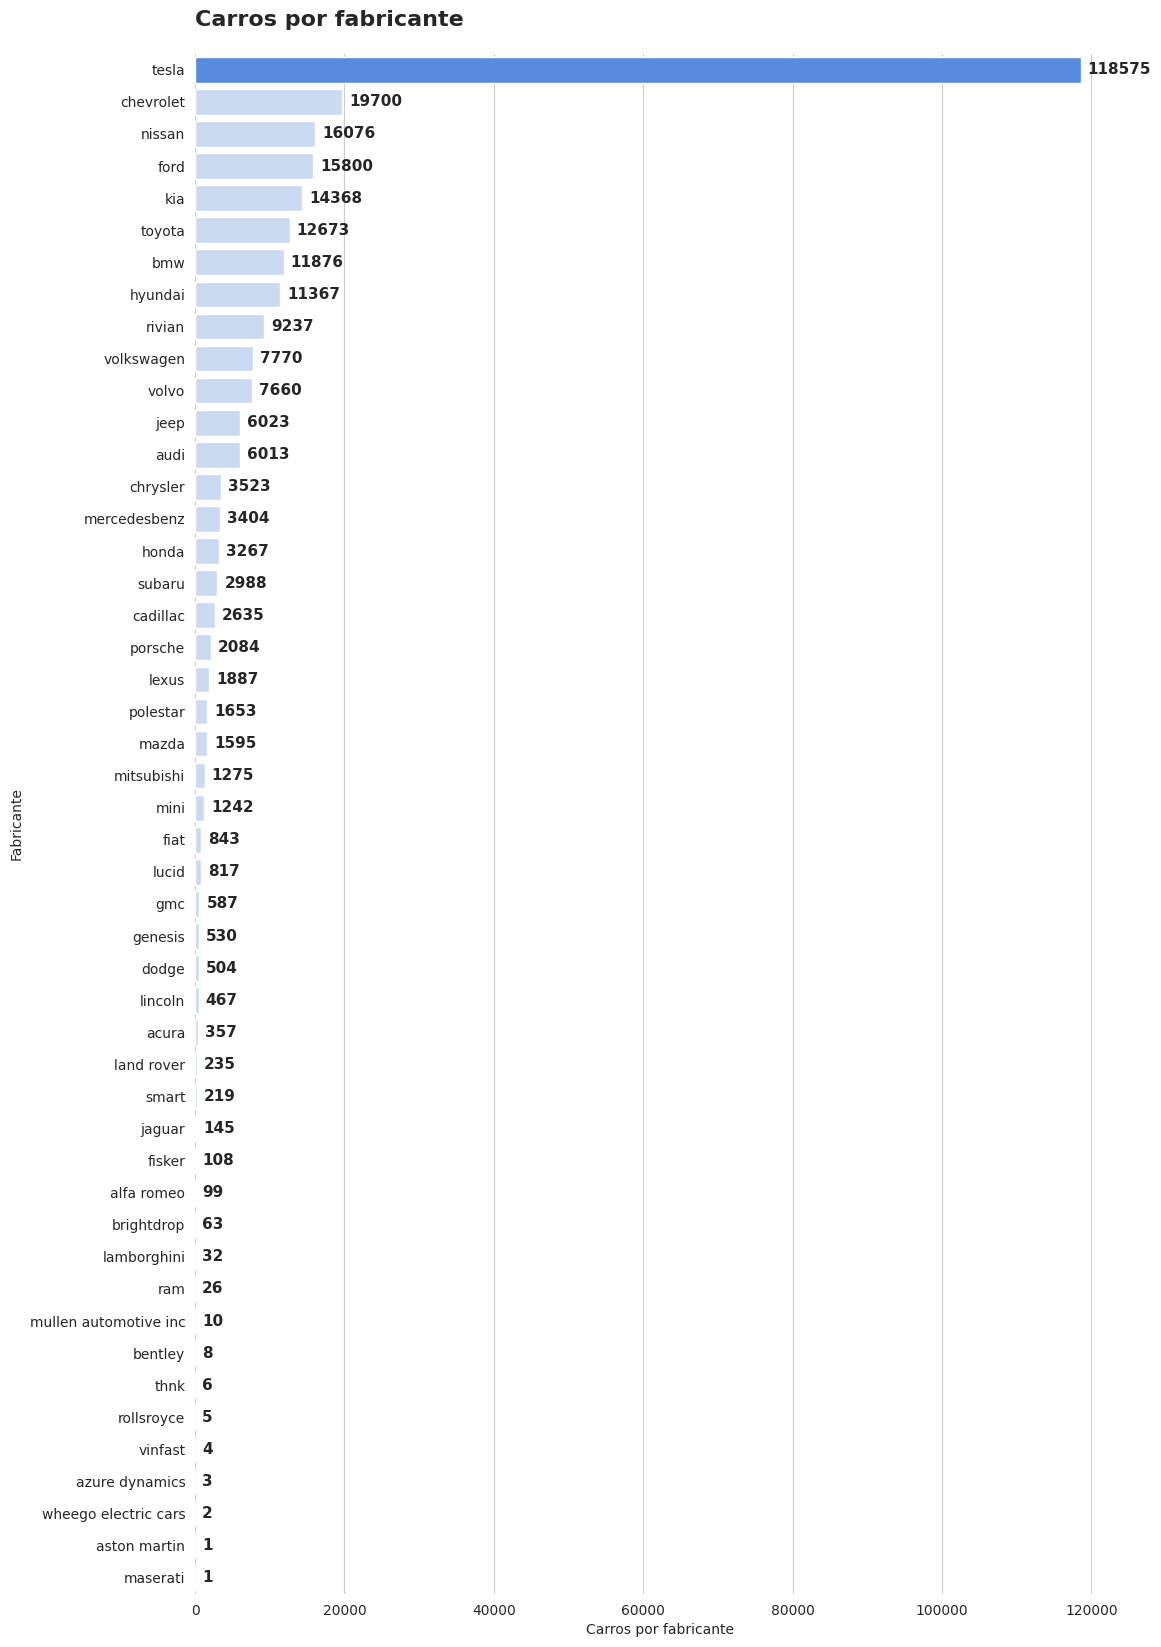

In [ ]:
# Realizar gráfico de barras

# Cuenta cuántos vehículos hay por marca y los ordena de mayor a menor
counts = df_ev_population_data_copy['Make'].value_counts()
order = counts.index   # Orden de las marcas
values = counts.values # Cantidad de vehículos por marca

# Asigna colores a las barras: azul para el máximo, gris claro para el mínimo, azul claro para el resto
colors = ['#4285F4' if v == values.max() else '#D3D3D3' if v == values.min() else '#C6D9F7' for v in values]

# Crea un lienzo de 12x20 pulgadas y aplica el estilo de cuadrícula
plt.figure(figsize=(12, 20))
sns.set_style("whitegrid")
ax = sns.barplot(x=values, y=order, palette=colors, hue=order, legend=False)  # Dibuja las barras horizontales

# Recorre cada barra y escribe el número de vehículos al final de ella
for p in ax.patches:
    ax.annotate(f'{int(p.get_width())}',                          # Texto a mostrar (cantidad de vehículos)
                (p.get_width(), p.get_y() + p.get_height() / 2),  # Posición: al final de la barra, centrado verticalmente
                ha='left', va='center', fontsize=11, fontweight='bold', xytext=(5, 0), textcoords='offset points')  # Estilo del texto y pequeño desplazamiento a la derecha

plt.title('Carros por fabricante', loc='left', fontsize=16, fontweight='bold', pad=20)  # Título alineado a la izquierda
plt.xlabel('Carros por fabricante')  # Etiqueta del eje horizontal
plt.ylabel('Fabricante')             # Etiqueta del eje vertical
sns.despine(left=True, bottom=True)  # Elimina los bordes izquierdo e inferior de la gráfica
plt.show()  # Muestra la gráfica

Ahora podemos ver cuantos vehículos hay registrados en Washington por fabricante. Es lógico que, quien tiene un rango de independencia más alto sea quien más vehículos venda. Aunque no se peude asegurar que esta sea la única razón para las ventas de Tesla, es entendible que la gente busque carros con la mayor independencia.

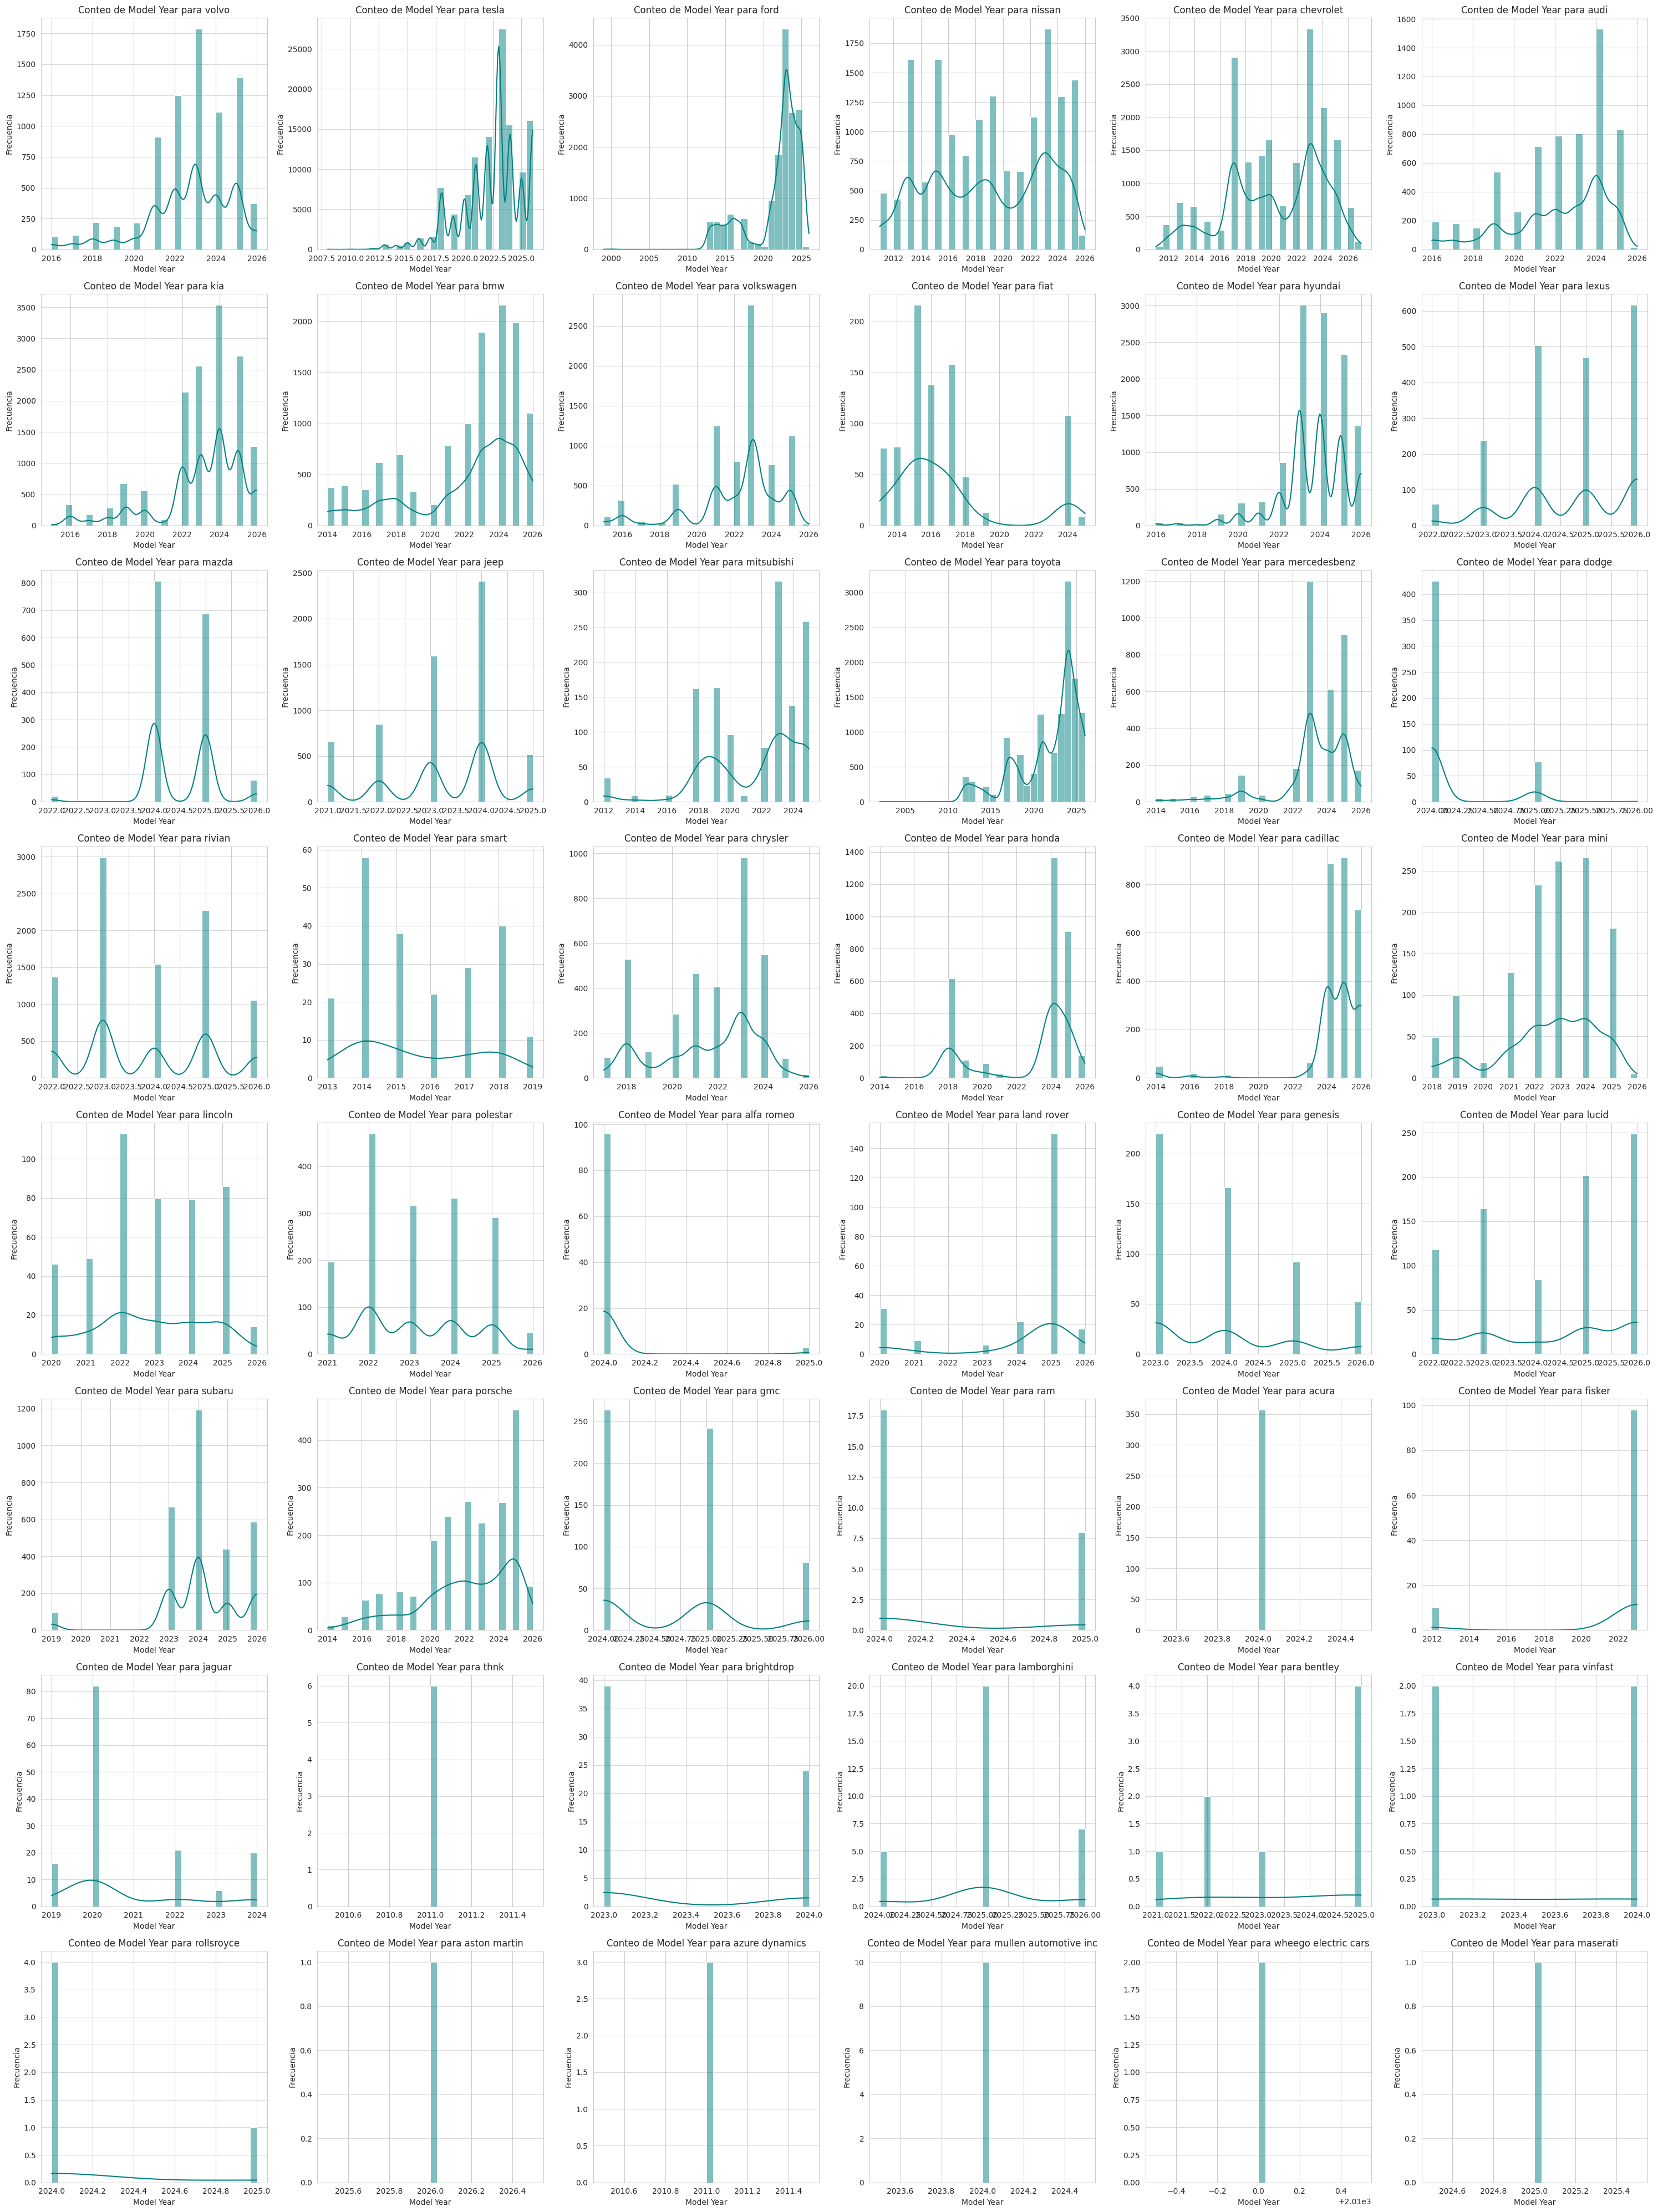

In [ ]:
# Crea un lienzo grande para mostrar múltiples gráficas
plt.figure(figsize=(30, 40))

col_revisar = 'Make'        # Columna que define cada gráfica (una por cada marca)
col_conteos = 'Model Year'  # Columna que se va a graficar en cada histograma

# Recorre cada marca única y crea un histograma por cada una
for i, col in enumerate(df_ev_population_data_copy[col_revisar].unique(), 1):
    plt.subplot(8, 6, i)  # Divide el lienzo en 8 filas y 6 columnas, coloca la gráfica en la posición i

    # Filtra los datos de la marca actual y dibuja el histograma del año de modelo
    sns.histplot(df_ev_population_data_copy[df_ev_population_data_copy[col_revisar] == col][col_conteos], bins=30, kde=True, color='teal')

    plt.title(f'Conteo de {col_conteos} para {col}')  # Título con el nombre de la marca
    plt.xlabel(col_conteos)      # Etiqueta del eje horizontal
    plt.ylabel('Frecuencia')     # Etiqueta del eje vertical
    plt.grid(axis='y', alpha=0.75)  # Líneas de cuadrícula horizontales con algo de transparencia

plt.tight_layout()  # Ajusta el espaciado para que las gráficas no se encimen
plt.show()          # Muestra todas las gráficas

Ahora podemos ver la frecuencia con la que los modelos de los fabricantes aparecen, usando el año del modelo como referencia. Aunque la mayoría tiene muy pocos modelos como para ver tendencias en al evolución temporal, los que sí los tienen, se ve que sus modelos más actuales tienen mayor éxito.

In [ ]:
# Crea una tabla cruzada que muestra cuántos vehículos hay por cada combinación de año y marca
tabla = df_ev_population_data_copy.pivot_table(
    index='Model Year',   # Las filas representan el año del modelo
    columns='Make',       # Las columnas representan cada marca
    aggfunc='size',       # Cuenta cuántos registros hay en cada combinación
    fill_value=0          # Rellena con 0 donde no hay vehículos de esa marca en ese año
)

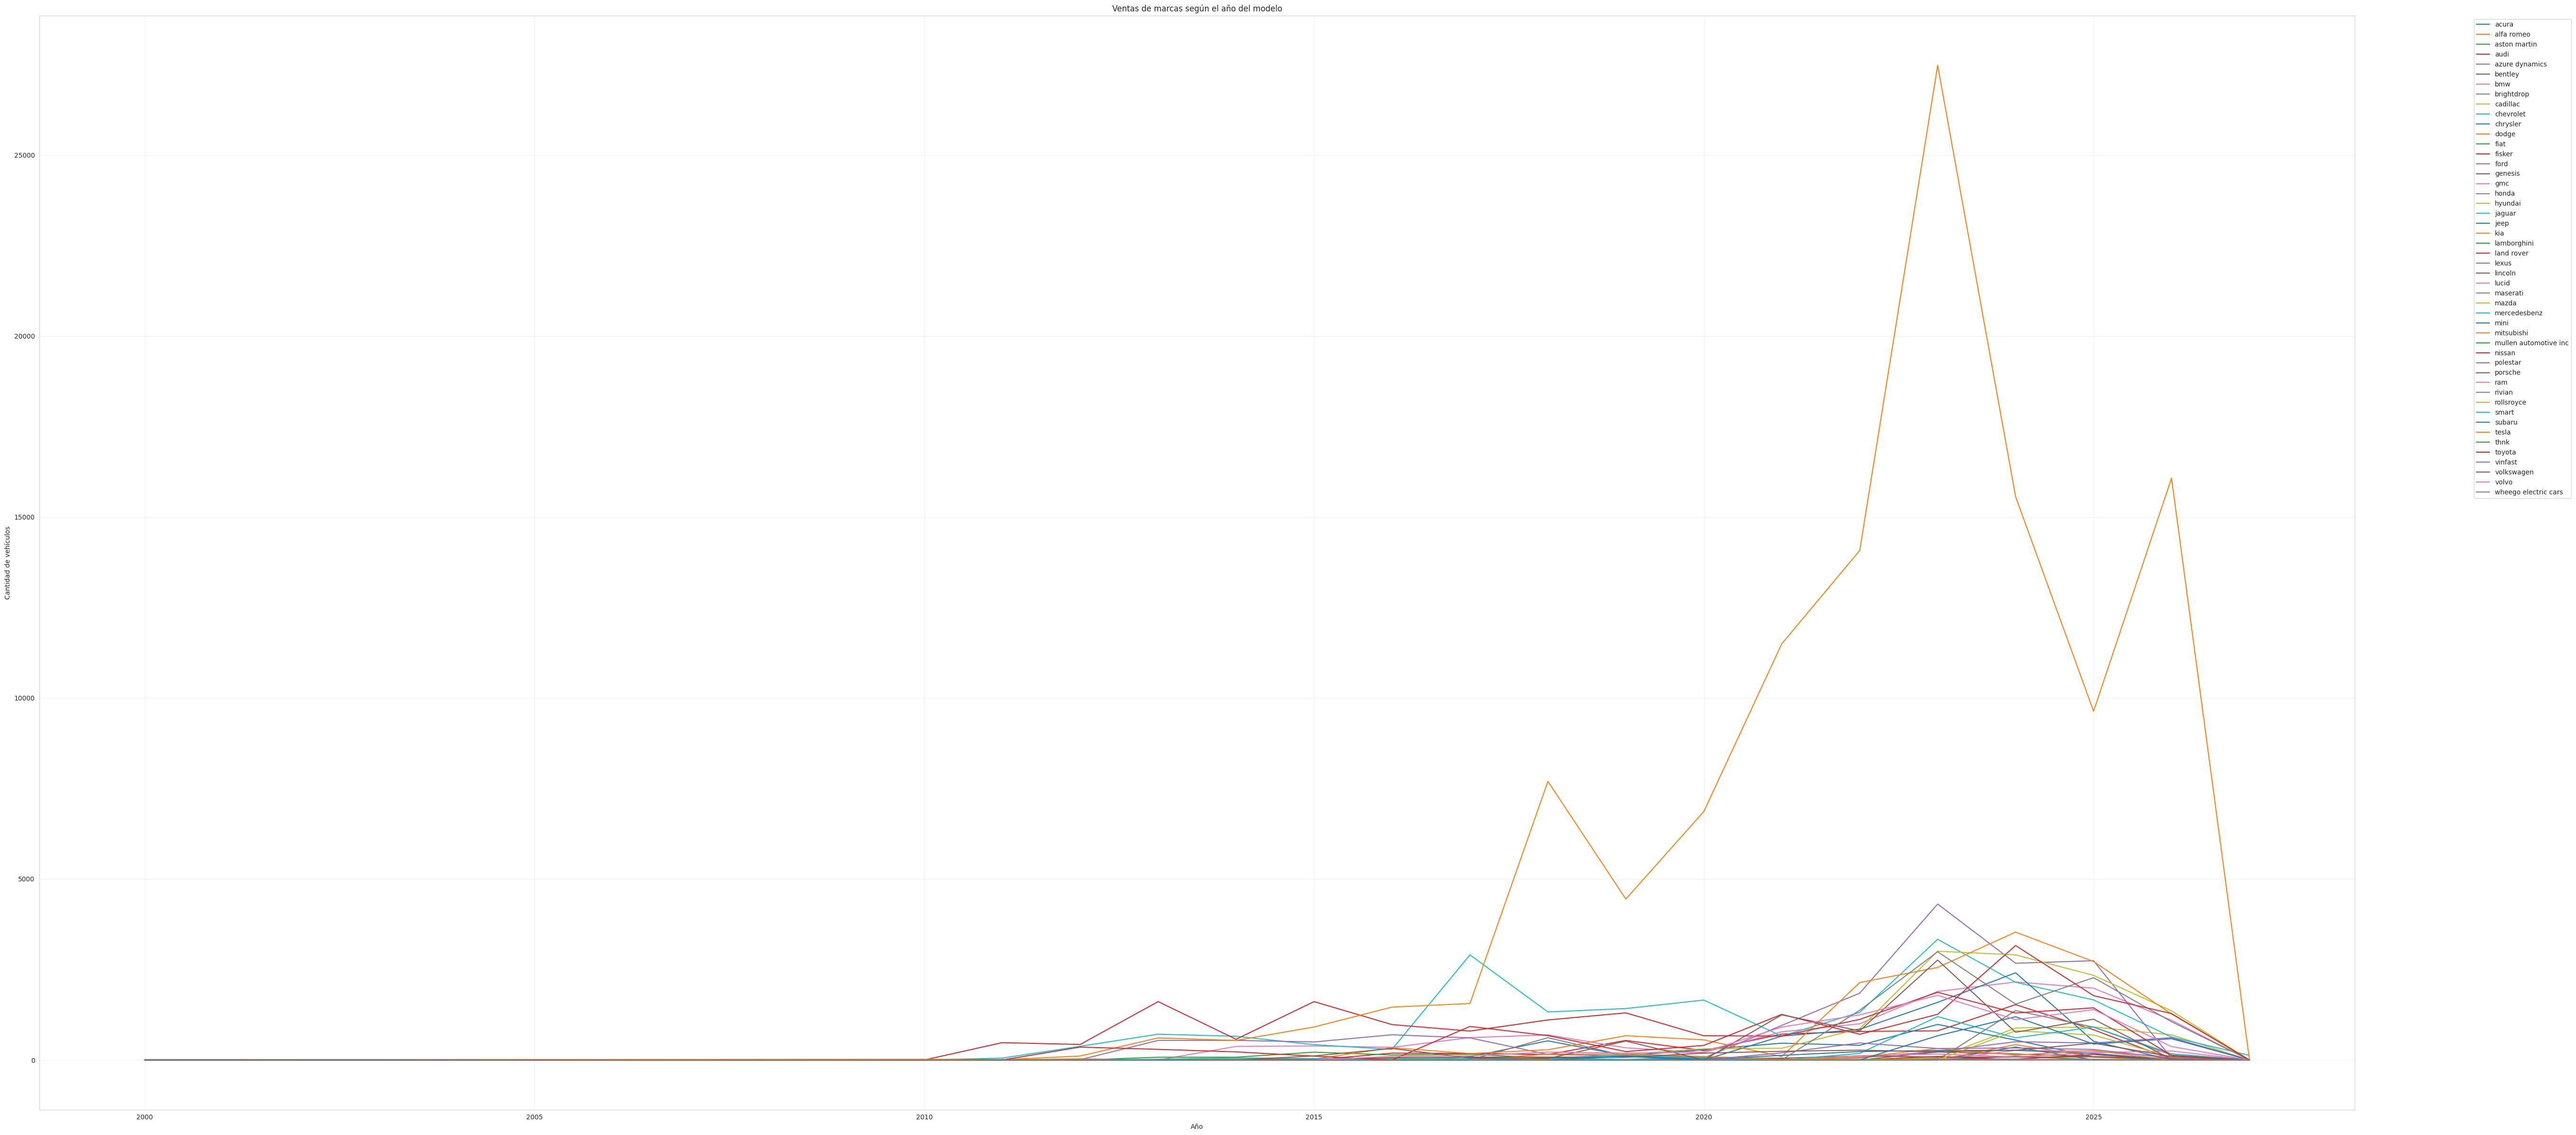

In [ ]:
# Elimina el año 1999 de la tabla y dibuja una gráfica de líneas para cada marca
tabla.drop([1999], axis=0).plot(figsize=(54, 24))  # Se excluye 1999 por ser un dato aislado que distorsiona la gráfica

plt.title('Ventas de marcas según el año del modelo')   # Título de la gráfica
plt.xlabel('Año')                                       # Etiqueta del eje horizontal
plt.ylabel('Cantidad de vehículos')                     # Etiqueta del eje vertical
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')  # Coloca la leyenda fuera de la gráfica a la derecha
plt.grid(alpha=0.3)                                     # Agrega cuadrícula con bastante transparencia
plt.tight_layout()                                      # Ajusta el espaciado para que todo se vea bien
plt.show()                                              # Muestra la gráfica

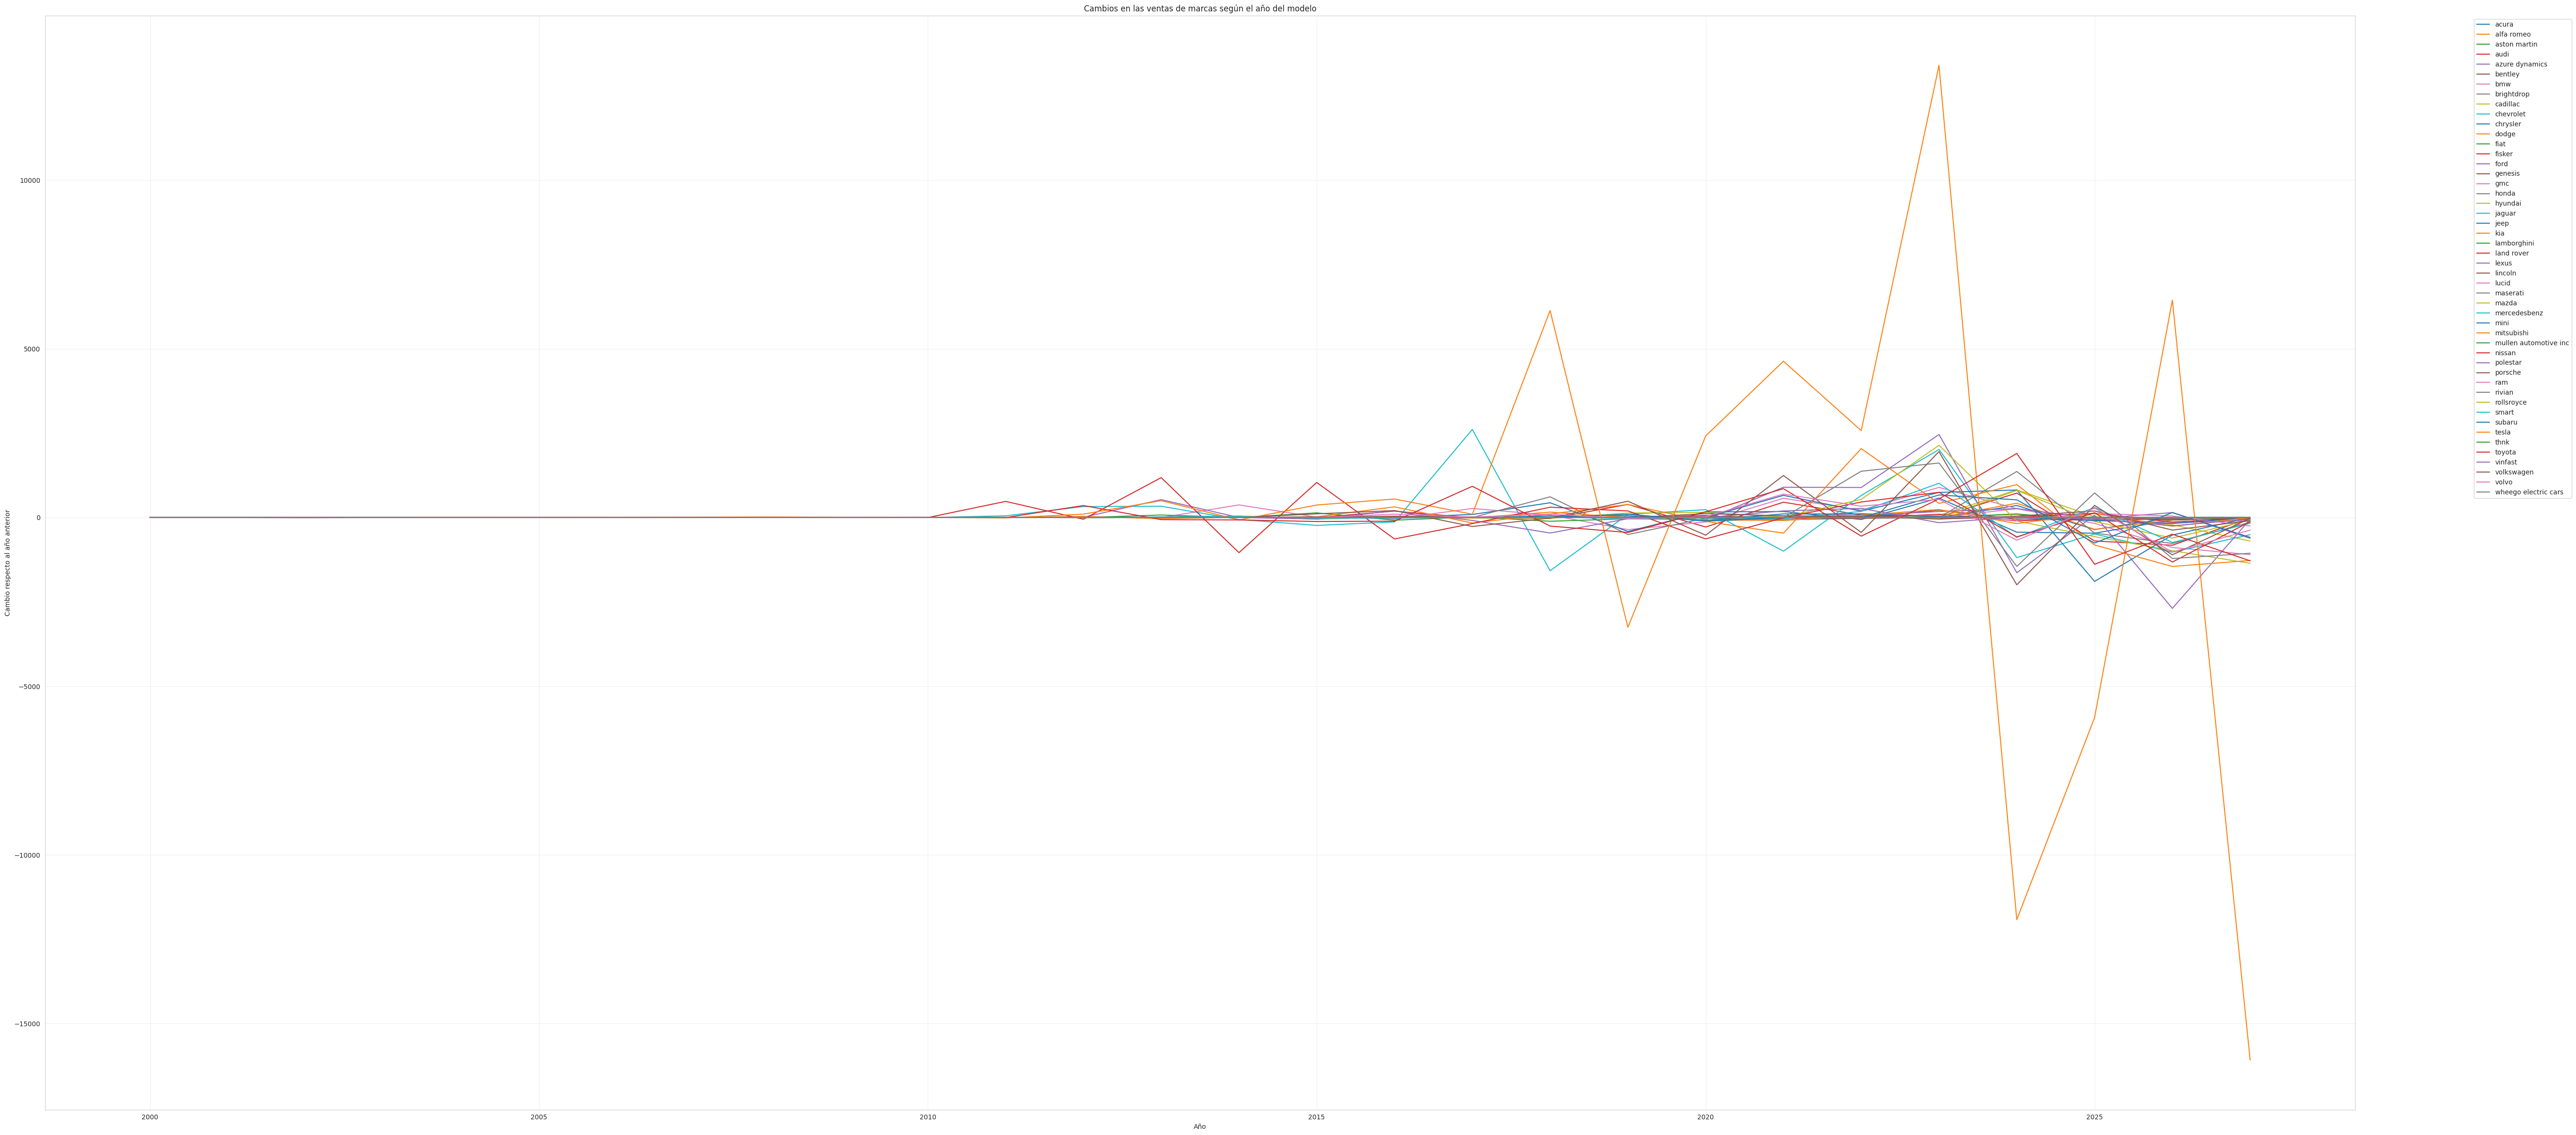

In [ ]:
# Calcula la diferencia de vehículos entre un año y el anterior para ver el crecimiento o caída de cada marca
tabla_diff = tabla.diff()

# Dibuja una gráfica de líneas con los cambios año a año de cada marca
tabla_diff.plot(figsize=(54, 24))

plt.title('Cambios en las ventas de marcas según el año del modelo')           # Título de la gráfica
plt.xlabel('Año')                                                              # Etiqueta del eje horizontal
plt.ylabel('Cambio respecto al año anterior')                                  # Etiqueta del eje vertical
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')                         # Coloca la leyenda fuera de la gráfica a la derecha
plt.grid(alpha=0.3)                                                            # Agrega cuadrícula con bastante transparencia
plt.tight_layout()                                                             # Ajusta el espaciado para que todo se vea bien
plt.show()                                                                     # Muestra la gráfica

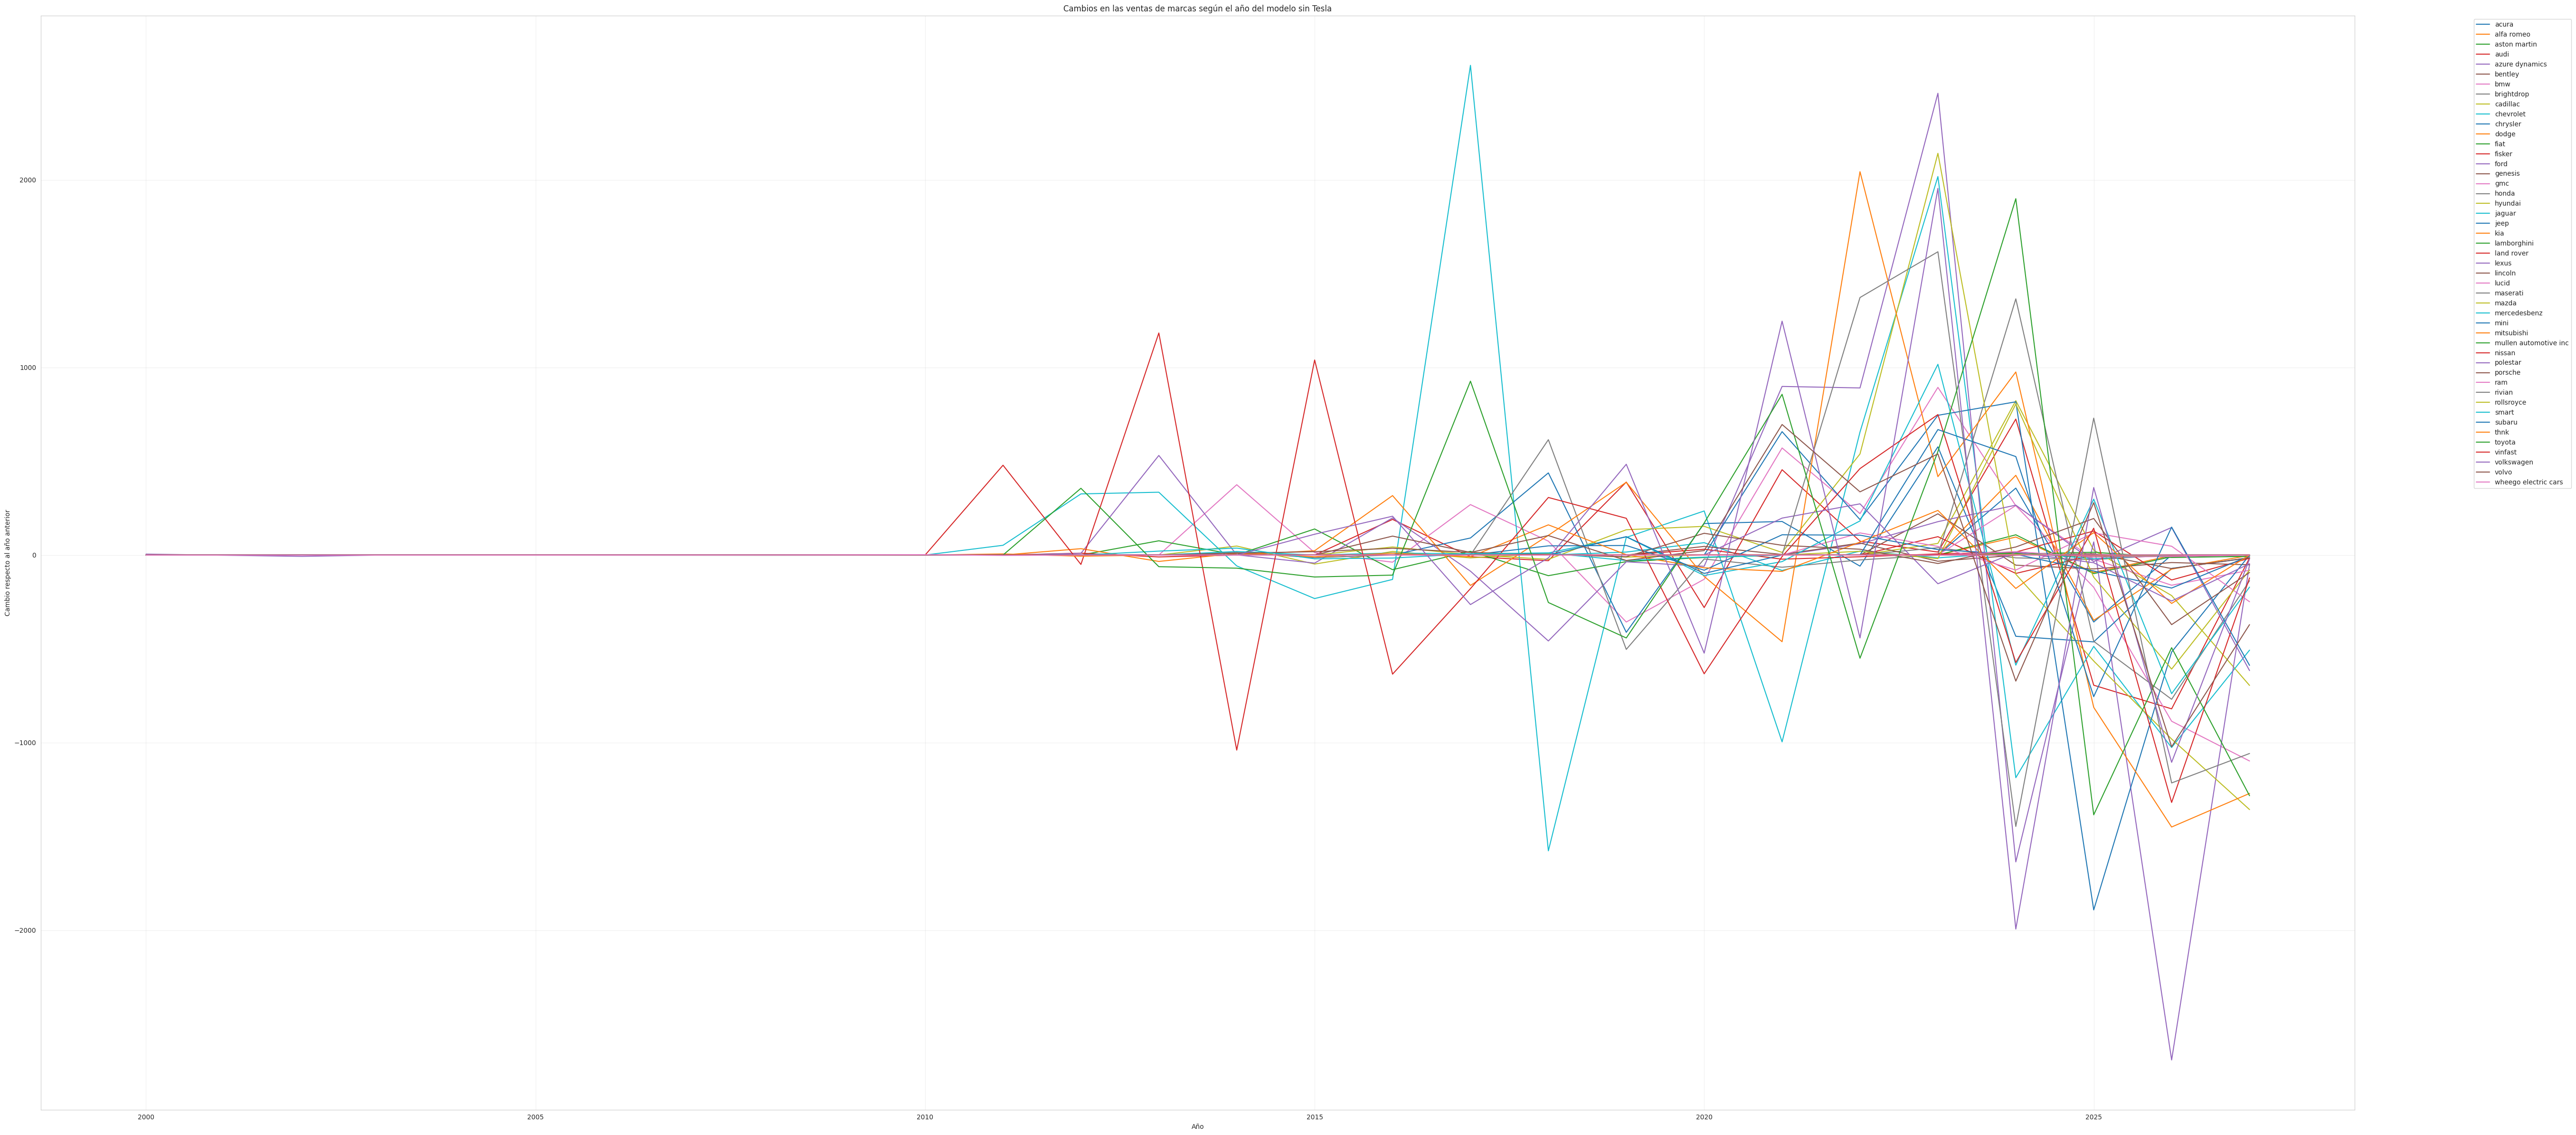

In [ ]:
# Calcula la diferencia de vehículos entre un año y el anterior para ver el crecimiento o caída de cada marca
tabla_diff = tabla.diff()

# Dibuja la gráfica excluyendo a Tesla, ya que su volumen es tan grande que opaca al resto de las marcas
tabla_diff.drop(columns=['tesla']).plot(figsize=(54, 24))

plt.title('Cambios en las ventas de marcas según el año del modelo sin Tesla')           # Título de la gráfica
plt.xlabel('Año')                                                                        # Etiqueta del eje horizontal
plt.ylabel('Cambio respecto al año anterior')                                            # Etiqueta del eje vertical
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')                                   # Coloca la leyenda fuera de la gráfica a la derecha
plt.grid(alpha=0.3)                                                                      # Agrega cuadrícula con bastante transparencia
plt.tight_layout()                                                                       # Ajusta el espaciado para que todo se vea bien
plt.show()                                                                               # Muestra la gráfica

En estas tres gráficas podemos ver con que los modelos más actuales, tienen mejores ventas que los modelos anteriores. Aunque parece haber una baja en las ventas en los dos años más recientes. Las gráficas no son sobre ventas por año, sino, sobre que tantas han tenido los modelos de cierto año hasta el día de hoy.

Como los modelos anteriores pueden seguir a la venta hoy en día, las ventas actuales se suman a las anteriores. De igual forma, puede ser que las ventas se hayan reducido actualmente, pero no es algo seguro.

#Aprendizaje Automático

##Regresión lineal y Descenso de gradiente 1

Uno de los factores para el incremento de las ventas de los modelos de años más recientes puede ser el aumento en el rango de los vehículos. Para esto vamos a explorar la correlación entre el año del modelo y el rango del mismo. Usaremos la regresión linela para esto.

In [ ]:
# Toma el año del modelo como variable independiente (lo que se usa para predecir)
x = df_ev_population_data_copy['Model Year']

# Toma el rango eléctrico como variable dependiente (lo que se quiere predecir)
y = df_ev_population_data_copy['Electric Range']

# Calcula la línea recta que mejor se ajusta a los datos (regresión lineal de grado 1)
linear_regression = np.polyfit(x, y, 1)

# Separa los dos valores que definen la recta: beta es la pendiente y alpha es el punto de inicio
beta, alpha = linear_regression

# Muestra la ecuación de la recta resultante
print(f'y = {beta} x + {alpha}')

y = -0.2859353790825917 x + 723.178617750917


In [ ]:
# Calculo del descenso de gradiente
tamaño_paso = 1e-7  # Qué tan grandes son los ajustes en cada iteración (valor muy pequeño para no pasarse)
theta_0 = 0         # Punto de inicio de la recta (intercepto), empieza en 0
theta_1 = 0         # Pendiente de la recta, empieza en 0

perdida = []  # Lista para guardar el error en cada iteración y ver cómo va mejorando

n = len(df_ev_population_data_copy['Model Year'])  # Número total de registros

num_iteraciones = 2000  # Cuántas veces se va a ajustar la recta

for i in range(num_iteraciones):
    y_pred = theta_1 * x + theta_0              # Calcula el rango eléctrico predicho con los valores actuales de la recta
    error = ((y_pred - y) ** 2).mean()          # Calcula qué tan equivocadas están las predicciones (error cuadrático medio)
    perdida.append(error)                        # Guarda el error de esta iteración

    d_theta_0 = (2 / n) * np.sum(y_pred - y)        # Calcula cuánto hay que ajustar el punto de inicio
    d_theta_1 = (2 / n) * np.sum((y_pred - y) * x)  # Calcula cuánto hay que ajustar la pendiente

    theta_0 = theta_0 - tamaño_paso * d_theta_0  # Ajusta el punto de inicio en la dirección correcta
    theta_1 = theta_1 - tamaño_paso * d_theta_1  # Ajusta la pendiente en la dirección correcta

# Muestra la ecuación de la recta final después de todos los ajustes
print(f'y = {theta_1} x + {theta_0}')

y = 0.07168221503887678 x + 3.611644057500323e-05


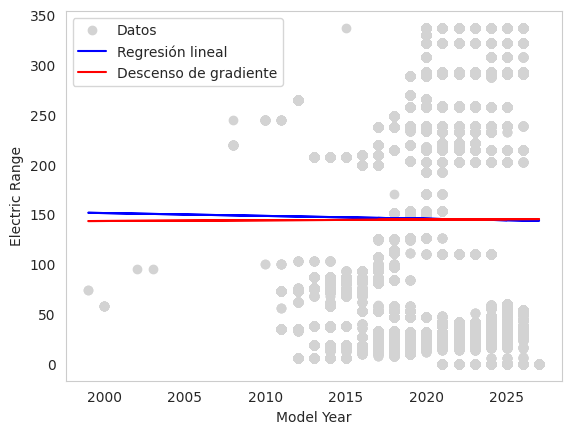

In [ ]:
# Visualizar regresión lineal y perdidas

# Grafica los datos reales como puntos grises
plt.plot(x, y, 'o', color='lightgray', label='Datos')

# Grafica la recta calculada con regresión lineal (numpy) en azul
plt.plot(x, beta*x + alpha, color='blue', label='Regresión lineal')

# Grafica la recta calculada con descenso de gradiente en rojo
plt.plot(x, theta_1 * x + theta_0, color='red', label='Descenso de gradiente')

plt.xlabel('Model Year')   # Etiqueta del eje horizontal
plt.ylabel('Electric Range')  # Etiqueta del eje vertical
plt.legend()  # Muestra la leyenda que identifica cada línea
plt.grid()    # Agrega cuadrícula
plt.show()    # Muestra la gráfica

Como lo marcaba la correlación que obtuvimos anteriormente, parece no haber un incremento en el rango a medida que pasa el tiempo.

Sin embargo, en los datos que usamos para la regresión tenemos los datos de los vehículos híbridos. Los vehículos híbridos no tiene como próposito tener mucha autonomía con la carga eléctrica, esto peude alterar nuestra regresión.

Además, tenemos lo vehículos que tienen un rango de 0, cuando esto no es algo razonable. Por lo menos, no es razonable usarlo para este análisis.

##Regresión lineal y Descenso de gradiente 2

Haremos un segundo inetento omitiendo los datos que discutimos antes.

In [ ]:
# Define un filtro para quedarse solo con vehículos 100% eléctricos y con rango mayor a 0
mask = (df_ev_population_data_copy['Electric Range'] != 0) & \
       (df_ev_population_data_copy['Electric Vehicle Type'] == 'battery electric vehicle bev')

# Aplica el filtro y extrae las columnas a usar
x = df_ev_population_data_copy.loc[mask, 'Model Year']      # Año del modelo como variable independiente
y = df_ev_population_data_copy.loc[mask, 'Electric Range']  # Rango eléctrico como variable dependiente

# Calcula la línea recta que mejor se ajusta a estos datos filtrados
linear_regression = np.polyfit(x, y, 1)

# Separa la pendiente y el punto de inicio de la recta
beta, alpha = linear_regression

# Muestra la ecuación de la recta resultante
print(f'y = {beta} x + {alpha}')

y = 14.19712142872163 x + -28438.19393431719


In [ ]:
# Esta vez el descenso de gradiente arranca desde los valores calculados por la regresión lineal
# en lugar de cero, para que converja más rápido a la solución óptima
tamaño_paso = 1e-7          # Qué tan grandes son los ajustes en cada iteración
theta_0 = 14.19712142872163      # Punto de inicio de la recta (tomado de la regresión lineal anterior)
theta_1 = -28438.19393431719     # Pendiente de la recta (tomado de la regresión lineal anterior)

perdida = []  # Lista para guardar el error en cada iteración

n = len(df_ev_population_data_copy['Model Year'])  # Número total de registros

num_iteraciones = 2000  # Cuántas veces se va a ajustar la recta

for i in range(num_iteraciones):
    y_pred = theta_1 * x + theta_0              # Calcula el rango eléctrico predicho
    error = ((y_pred - y) ** 2).mean()          # Calcula el error de las predicciones
    perdida.append(error)                        # Guarda el error de esta iteración

    d_theta_0 = (2 / n) * np.sum(y_pred - y)        # Calcula cuánto ajustar el punto de inicio
    d_theta_1 = (2 / n) * np.sum((y_pred - y) * x)  # Calcula cuánto ajustar la pendiente

    theta_0 = theta_0 - tamaño_paso * d_theta_0  # Ajusta el punto de inicio
    theta_1 = theta_1 - tamaño_paso * d_theta_1  # Ajusta la pendiente

# Muestra la ecuación de la recta final
print(f'y = {theta_1} x + {theta_0}')

y = 0.1165563646966196 x + 28.263748960093977


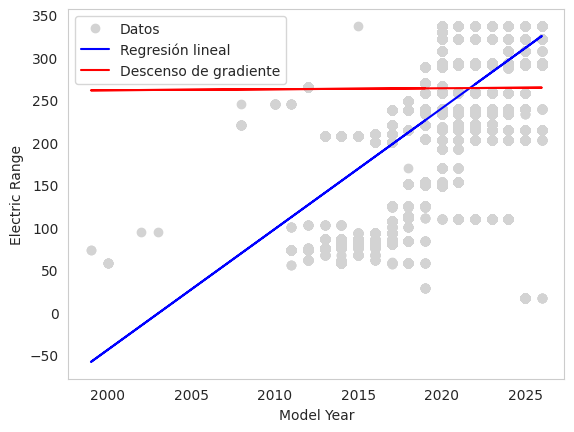

In [ ]:
# Grafica los datos reales como puntos grises
plt.plot(x, y, 'o', color='lightgray', label='Datos')

# Grafica la recta calculada con regresión lineal (numpy) en azul
plt.plot(x, beta*x + alpha, color='blue', label='Regresión lineal')

# Grafica la recta calculada con descenso de gradiente en rojo
# Esta vez ambas rectas deberían ser casi idénticas ya que el gradiente partió desde los valores de la regresión lineal
plt.plot(x, theta_1 * x + theta_0, color='red', label='Descenso de gradiente')

plt.xlabel('Model Year')      # Etiqueta del eje horizontal
plt.ylabel('Electric Range')  # Etiqueta del eje vertical
plt.legend()  # Muestra la leyenda que identifica cada línea
plt.grid()    # Agrega cuadrícula
plt.show()    # Muestra la gráfica

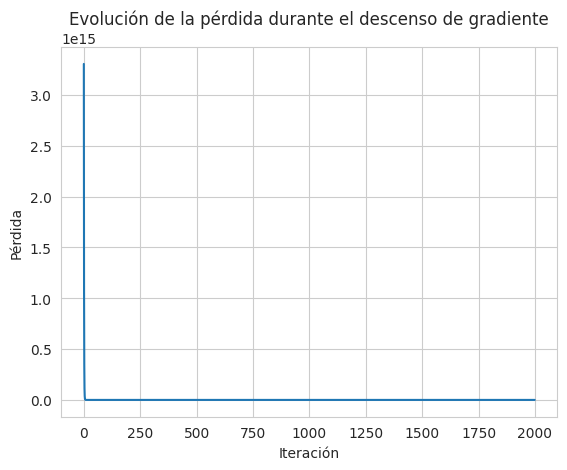

In [ ]:
# Registro final de perdida
plt.plot(perdida)
plt.title('Evolución de la pérdida durante el descenso de gradiente')
plt.xlabel('Iteración')
plt.ylabel('Pérdida')
plt.show()

In [ ]:
# Calcula la correlación entre el año del modelo y el rango eléctrico
# El resultado es una matriz 2x2 donde el valor importante está en la posición [0,1] o [1,0]
# y va de -1 (correlación negativa perfecta) a 1 (correlación positiva perfecta)
coeficiente = np.corrcoef(x, y)
print('r=', coeficiente[0,1], 'r^2=', coeficiente[0,1]**2.0)

r= 0.7127692043866867 r^2= 0.5080399387220303


Al eliminar los datos, el coeficiente de correlación incrementó considerablemente. Sí hay una tendencia a la alta en el rango de los vehículos a medida que avanza el tiempo, de $R^2$ sabemos que la regresión lineal no es la mejor erramienta para modelar este crecimiento, pero la tendencia a la alta es clara.

Las carencias de la regreción lineal para modelar este comportamiento se pueden ver en el uso del método de descenso del gradiente con una ecuación lienal.

##K-Nearest Neighbors

In [ ]:
# Guarda una copia del dataframe original antes de cualquier modificación para poder consultarlo si es necesario
df_ev_population_data_original = df_ev_population_data.copy()

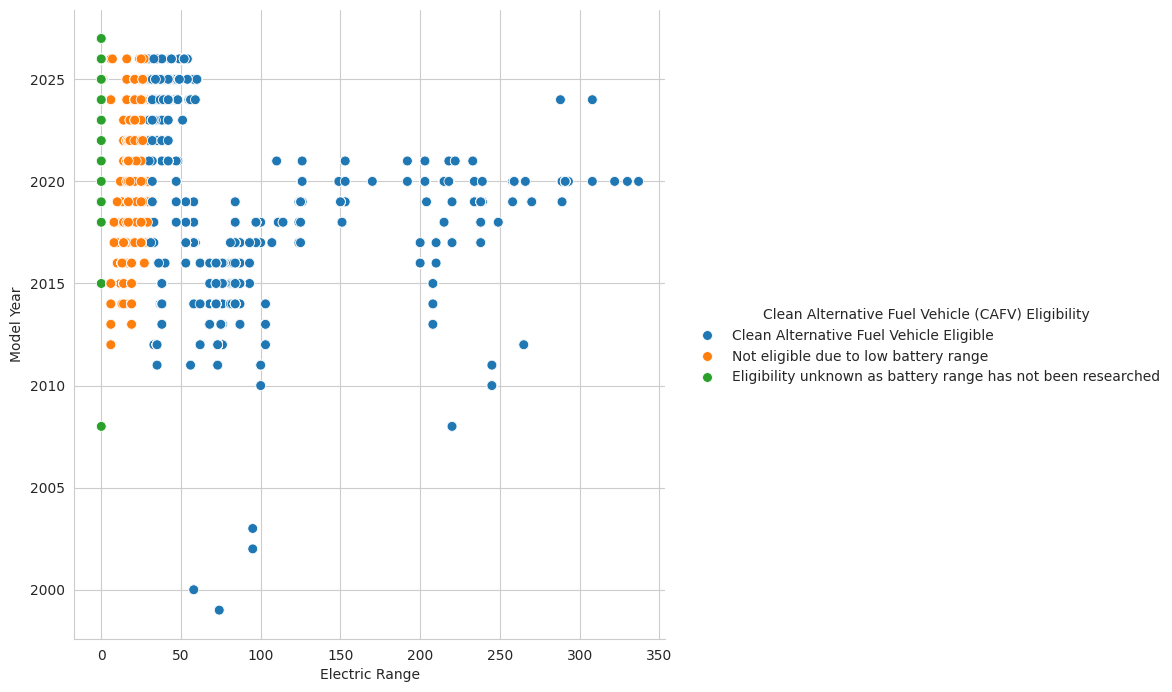

In [ ]:
# Grafica la relación entre 'Electric Range' y 'Model Year' coloreando los puntos según
# la elegibilidad del vehículo como combustible alternativo limpio (CAFV)
sns.pairplot(x_vars='Electric Range', y_vars='Model Year', data=df_ev_population_data,
             plot_kws={'s': 50},  # Tamaño de cada punto en la gráfica
             height=7,            # Altura de la gráfica en pulgadas
             hue='Clean Alternative Fuel Vehicle (CAFV) Eligibility')  # Color según la categoría de elegibilidad

In [ ]:
# Asigna el valor 6.0 en la columna 'Electric Range' a todos los vehículos cuyo modelo es 'REVUELTO'
df_ev_population_data.loc[df_ev_population_data['Model'] == 'REVUELTO', 'Electric Range'] = 6.0

# Asigna el valor 6.0 en la columna 'Electric Range' a todos los vehículos cuyo modelo es 'TEMERARIO'
df_ev_population_data.loc[df_ev_population_data['Model'] == 'TEMERARIO', 'Electric Range'] = 6.0

In [ ]:
# Selecciona las columnas numéricas que se usarán como variables de entrada para el modelo KNN
x = df_ev_population_data[['Electric Range', 'Model Year']]

In [ ]:
# Selecciona la columna que el modelo KNN intentará predecir (la etiqueta o variable objetivo)
y = df_ev_population_data['Clean Alternative Fuel Vehicle (CAFV) Eligibility']

In [ ]:
# Importa la herramienta para dividir los datos en entrenamiento y prueba
from sklearn.model_selection import train_test_split

# Divide los datos en dos partes:
# - 80% para entrenar el modelo (x_train, y_train)
# - 20% para probar qué tan bien aprendió (x_test, y_test)
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2)

In [ ]:
# Muestra cuántos registros quedaron en cada parte de la división
print(len(x_train), len(x_test))

230210 57553


In [ ]:
# Calcula la raíz cuadrada del número de registros de entrenamiento
# Es una forma común de estimar un valor inicial para K en el KNN
import math
math.sqrt(len(x_train))

479.80204251336824

In [ ]:
# Importa la herramienta para normalizar los datos
from sklearn.preprocessing import MinMaxScaler

# Crea el normalizador que convertirá todos los valores a un rango entre 0 y 1
scaler = MinMaxScaler(feature_range=(0, 1))

# Aprende los valores mínimos y máximos de los datos de entrenamiento
# (solo se entrena con x_train para evitar que el modelo "vea" los datos de prueba)
scaler.fit(x_train)

MinMaxScaler()

In [ ]:
# Aplica la normalización a los datos de entrenamiento usando los valores aprendidos anteriormente
x_train = scaler.transform(x_train)

# Aplica la misma normalización a los datos de prueba
# (se usa el mismo scaler del x_train para que ambos estén en la misma escala)
x_test = scaler.transform(x_test)

# Muestra cómo quedaron los datos de prueba después de normalizar
x_test

array([[0.        , 0.85714286],
       [0.        , 0.92857143],
       [0.95548961, 0.75      ],
       ...,
       [0.        , 0.78571429],
       [0.        , 0.92857143],
       [0.        , 0.89285714]])

In [ ]:
# Verifica que la normalización funcionó correctamente
# el mínimo debe ser 0 y el máximo debe ser 1
x_train.min(), x_train.max()

(np.float64(0.0), np.float64(1.0))

In [ ]:
# Importa el modelo KNN para clasificación
from sklearn.neighbors import KNeighborsClassifier

# Crea el modelo con 480 vecinos (valor estimado a partir de la raíz cuadrada del total de registros)
classifier = KNeighborsClassifier(n_neighbors=480)

# Entrena el modelo con los datos de entrenamiento normalizados
classifier.fit(x_train, y_train)

KNeighborsClassifier(n_neighbors=480)

In [ ]:
# Usa el modelo entrenado para predecir las etiquetas de los datos de prueba
y_pred = classifier.predict(x_test)

# Muestra las predicciones realizadas
y_pred

array(['Eligibility unknown as battery range has not been researched',
       'Eligibility unknown as battery range has not been researched',
       'Clean Alternative Fuel Vehicle Eligible', ...,
       'Eligibility unknown as battery range has not been researched',
       'Eligibility unknown as battery range has not been researched',
       'Eligibility unknown as battery range has not been researched'],
      dtype=object)

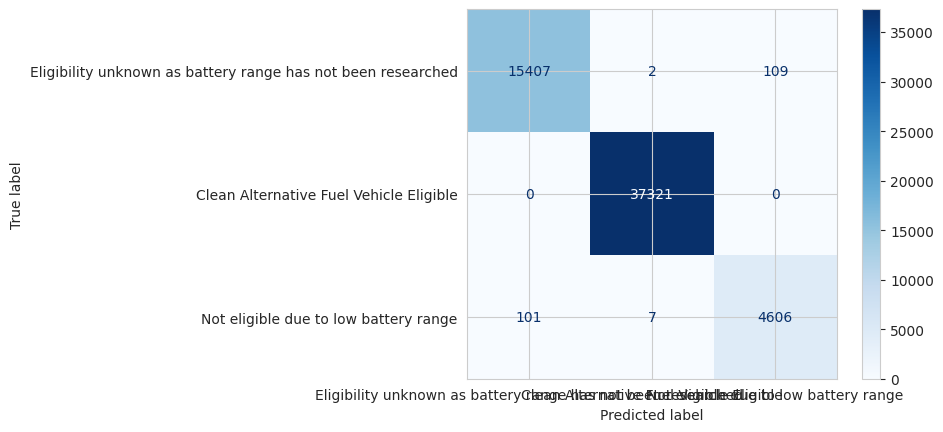

In [ ]:
# Importa la herramienta para visualizar la matriz de confusión
from sklearn.metrics import ConfusionMatrixDisplay

# Define los nombres de las tres categorías posibles que el modelo predice
class_names = ['Eligibility unknown as battery range has not been researched',  # Elegibilidad desconocida
               'Clean Alternative Fuel Vehicle Eligible',                        # Sí es elegible
               'Not eligible due to low battery range']                          # No elegible por bajo rango

normalize = None  # No normaliza los valores, muestra conteos reales

# Genera y muestra la matriz de confusión comparando las predicciones del modelo contra los valores reales
# Cada fila representa la categoría real y cada columna la categoría predicha
# Los valores en la diagonal son los aciertos del modelo
ConfusionMatrixDisplay.from_estimator(
        classifier,
        x_test,       # Datos de prueba normalizados
        y_test,       # Etiquetas reales
        display_labels=class_names,
        cmap=plt.cm.Blues,  # Escala de color azul
        normalize=normalize,
    )

In [ ]:
# Importa la herramienta para generar el reporte de métricas del modelo
from sklearn.metrics import classification_report

# Muestra un reporte detallado con las métricas de evaluación por cada categoría:
# - precision: de los que predijo como X, cuántos realmente eran X
# - recall: de los que realmente eran X, cuántos identificó correctamente
# - f1-score: promedio entre precision y recall
# - support: cuántos registros reales hay de cada categoría
print(classification_report(y_test, y_pred))

                                                              precision    recall  f1-score   support

                     Clean Alternative Fuel Vehicle Eligible       0.99      0.99      0.99     15518
Eligibility unknown as battery range has not been researched       1.00      1.00      1.00     37321
                       Not eligible due to low battery range       0.98      0.98      0.98      4714

                                                    accuracy                           1.00     57553
                                                   macro avg       0.99      0.99      0.99     57553
                                                weighted avg       1.00      1.00      1.00     57553



In [ ]:
# Lista para guardar el error de cada valor de K
error = []

# Prueba el modelo con diferentes valores de K entre 460 y 499
# para encontrar cuál genera menos errores
for i in range(460, 500):
    knn = KNeighborsClassifier(n_neighbors=i)  # Crea el modelo con K vecinos
    knn.fit(x_train, y_train)                  # Entrena el modelo
    pred_i = knn.predict(x_test)               # Genera predicciones con los datos de prueba
    error.append(np.mean(pred_i != y_test))    # Calcula y guarda el porcentaje de predicciones incorrectas

# Muestra la lista de errores por cada valor de K probado
error

[np.float64(0.0033013048841936997),
 np.float64(0.0033013048841936997),
 np.float64(0.0033013048841936997),
 np.float64(0.0033013048841936997),
 np.float64(0.0033013048841936997),
 np.float64(0.0033013048841936997),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.0038051882612548434),
 np.float64(0.00380518826125

Usamos el método de KNN para ver como podemos clasificar de manera exitosa los autos que se pueden usar como alternativas a vehículos convencionales. Estas clasificaciones se hacen usando el año del modelo y los rangos de estos modelos.

Con esto podemos concluir que es razonable esperar que a medida que los rangos de independencia de los vehículos eléctricos aumente, estos vehículos tendrán más éxito en el mercado del transporte para particulares. Es decir, hay que poner más esfuerzos en mejorar el rango de autonomía de los vehículos eléctricos.

Por lo menos en el estado de Washington, pero es razonable esperar el ver casos similares en otras partes de Estados Unidos. Para otras partes del mundo, sería útil incluir los precios y los precios relativos a los vehículos de combustibles fósiles.